# Detector de voz gerada por IA: o sistema v4 (F0), documento final

> **A frase do projeto:** um modelo de fala pronto e congelado (o XLS-R, da Meta) transforma cada áudio em números; uma **regressão logística** treinada por nós dá uma **nota** a cada áudio e, acima de um **corte**, chama a voz de gerada por IA; a avaliação seguiu regras anti-vazamento, e todas as versões foram reportadas.

## 1. Introdução

**Objetivo.** Dizer se uma voz foi gerada por IA. O treino é em inglês (estúdio e audiolivro); o teste inclui vozes de internet (In-the-Wild), fakes parciais (LlamaPartialSpoof) e português (BRSpeech-DF e CORAA).

**Resultados em 5 linhas** (todos lidos de `results/`; detalhes nas seções 7 e 8):
1. A CNN das versões 1 a 3 errava de forma sistemática nas vozes de internet: a AUC do In-the-Wild ficou entre 0,11 e 0,35, **abaixo de 0,5 (cara ou coroa)**, ou seja, ela dava nota de IA mais alta aos reais. Com o XLS-R congelado + regressão logística (v4), a AUC do In-the-Wild foi para **0,979** e a do dev_shift para **0,983**.
2. No teste (avaliado uma vez, na v4), a média da acurácia nos 3 bancos principais foi **0,851** (corte A) contra **0,597** do "chute da classe comum".
3. O modelo pronto fez a maior parte do trabalho: **só a última camada** (S1) já dava 0,843 de média; a diferença das nossas escolhas por cima **não foi demonstrada**.
4. O ponto fraco é o **português**: BRSpeech-DF com acurácia balanceada 0,679 (corte A) e CORAA com 16,7% de reais acusados (corte A).
5. Nada do que tentamos depois (v5: o WavLM da Microsoft no lugar do XLS-R; v6: fusão, MLP, CNN e ajuste fino) superou o F0 no teste: o sistema declarado pelo funil da v6 (F2) ficou pior. A volta ao F0 foi uma escolha informada pelo teste (seção 10), embora o F0 em si tenha sido escolhido pela validação antes de qualquer teste.

**Como ler.** Antes de cada figura, um parágrafo diz **o que ela mostra**; depois, **o que olhar** e **o que concluir** (com os limites). Cada bloco de código tem antes um parágrafo dizendo o que faz e por quê. Este notebook **só lê** arquivos já gravados: não treina, não extrai e não consulta o teste (`AVALIAR_TESTE_FINAL = False`); os números de teste são os gravados pela v4, que avaliou o teste uma única vez. As figuras foram geradas por `scripts/v4final_figuras.py` a partir dos caches da v4 e também estão em alta resolução em `results/slides/` (lista em `results/slides/INDEX.md`). Tudo o que não foi ensinado na trilha está marcado com "⚠️ Fora da trilha".

### Glossário em linguagem simples

As mesmas palavras são usadas em todas as figuras e explicações.

| palavra | o que quer dizer |
|:--|:--|
| **Real** / **gerada por IA** | voz humana gravada / voz criada ou modificada por um gerador de IA (nos arquivos, "fake" = gerada por IA) |
| **Mono** | um único canal de áudio (o estéreo tem dois). Todos os nossos áudios já são mono. |
| **Taxa de amostragem** | quantas medidas do som o arquivo guarda por segundo. 16 kHz = 16.000 medidas por segundo, o que registra sons até 8 kHz. Se os reais e os gerados por IA de um banco têm taxas diferentes, o modelo pode "acertar" só pelo formato do arquivo; por isso padronizamos tudo em 16 kHz. |
| **Log-mel** | uma imagem do som (tempo × frequência), com as frequências agrupadas em 64 faixas que imitam o ouvido e o brilho em escala logarítmica (figura 02). Era a entrada da CNN das versões 1 a 3. |
| **Convolução** / **pooling** | convolução: um filtro pequeno que desliza pela imagem procurando um padrão local. Pooling: reduz a imagem guardando o maior valor de cada pedacinho, o que dá tolerância a pequenos deslocamentos. |
| **XLS-R** | um modelo de fala pronto (da Meta), treinado sem rótulos em fala de 128 línguas. Usamos congelado: ele só transforma o áudio em números. |
| **Camada** | o XLS-R tem 24 camadas empilhadas; cada uma devolve um vetor de 1.024 números a cada 20 ms. A camada 0 é a entrada, a 24 é a última. |
| **Nota** e **corte** (limiar) | a regressão dá uma nota a cada áudio (quanto maior, mais parece IA); acima do corte, chamamos de IA. **Corte A** (calibrado no estúdio) = o ponto em que "reais acusados" e "gerados por IA que passam" têm a mesma taxa, na validação. **Corte B** (calibrado na internet) = o mesmo ponto, no dev_shift. |
| **AUC** | a chance de um áudio gerado por IA, sorteado do mesmo banco, receber nota mais alta que um real sorteado. 1 = sempre; **0,5 = cara ou coroa**; **abaixo de 0,5 = o modelo erra de forma sistemática** (dá nota de IA mais alta aos reais). Não depende do corte. |
| **EER** (taxa de erro igual) | o erro no corte em que "reais acusados" e "gerados por IA que passam" têm a mesma taxa; quanto menor, melhor. |
| **Acurácia** / **acurácia balanceada** | acurácia: % de acertos. Balanceada: a média do acerto nos reais e do acerto nos gerados por IA. Em banco desbalanceado, a acurácia sozinha engana: no dev_shift (81% real), chamar tudo de real já acerta 81% (o **chute da classe comum**). |
| **Validação** | áudios dos mesmos bancos do treino, mas de **outros locutores**; escolhe camada, C e o corte A. É o "estúdio". |
| **dev_shift** | 10.614 áudios do In-the-Wild (figuras públicas, reais e falsos coletados na internet) de 16 locutores, separados por pessoa; usado só para comparar versões e escolher o corte B. Os outros 38 locutores ficaram no teste. "shift" = a mudança do estúdio para a internet. |
| **Teste** | bancos que nunca entram no treino nem em escolha nenhuma; avaliados uma vez por versão. |
| **Fonte** | cada banco de origem dos áudios (DFADD, ShiftySpeech...). |
| **Falso parcial** | áudio com trechos gerados por IA dentro de uma fala real (LlamaPartialSpoof). |
| **Peso igual por fonte** | cada fonte conta o mesmo no treino da regressão, para a maior não dominar (testado na v6). |
| **Funil** (v6) | etapas em sequência; cada uma compara opções e só a vencedora passa para a próxima. |
| **C** | o "freio" da regularização da regressão: **C pequeno = freio forte** = pesos pequenos = regressão mais simples. |

## 2. Configuração

**O que faz:** a célula abaixo (tag `config`) é **a configuração da v4**, mais um bloco curto que diz onde este documento lê os valores do F0. Só os comentários que citavam o equipamento foram trocados por descrições neutras (o código é o mesmo, conferido pelo script que monta o notebook). **Por quê:** o F0 é a v4; os scripts da v4 (`scripts/v4.py`, `scripts/v4_teste.py`) executam esta célula para saber os hiperparâmetros, então ela tem de continuar sendo a da v4. `AVALIAR_TESTE_FINAL = False`: nada aqui consulta o teste.

In [1]:
import json
import os
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd

from src.analysis import FAIXAS_DURACAO, faixa_duracao
from src.metrics import eer_e_limiar, eer_media_por_fonte, metricas_completas

# ---------------- execução ----------------
QUICK = False                # True: teste rápido de ponta a ponta (~300 clipes, arquivos _quick)
QUICK = globals().get("QUICK_DO_SCRIPT", QUICK or os.environ.get("V4_QUICK") == "1")  # --quick / V4_QUICK=1
AVALIAR_TESTE_FINAL = False  # False: NADA do teste final é consultado nesta versão
VERSAO = "v4"

# ---------------- herdados (sem mudança) ----------------
SEED = 42                    # seed dos DADOS (amostras e sorteio dos shards de treino)
SAMPLE_RATE = 16_000
NUM_WORKERS = 4              # leitura de áudio; sobrescrito por V4_NUM_WORKERS (não muda o método)

# ---------------- modelo congelado (Parte C) ----------------
MODELO_SSL = "facebook/wav2vec2-xls-r-300m"
DTYPE = "float16"            # metade da memória e ~2x mais rápido; lote com NaN é refeito em bfloat16

# ---------------- pré-processamento (Parte D) ----------------
TOP_DB = 35.0                # corte do silêncio: quadros 35 dB abaixo do mais forte
MIN_S = 0.5                  # se o corte deixar menos que isso, usa o áudio sem corte
MAX_S = 8.0                  # recorte central de no máximo 8 s (sem completar)

# ---------------- extração (Parte D) ----------------
ORCAMENTO_H = 4.0            # orçamento CUMULATIVO de extração (results/v4_estado.json)
TAM_SHARD = 2000             # clipes por shard (~1 min de extração cada)
VAL_MAX = 20_000             # subamostra da validação
VAL_FONTE_PEQUENA = 5_000    # fontes com até isso entram inteiras (CodecFake+ e ShiftySpeech)
DEV_MAX = None               # None = dev_shift inteiro
TREINO_MAX_SHARDS = 20       # 40.000 clipes (20.000 reais + 20.000 fakes): o teto por fonte ainda vale
SEMCORTE = dict(treino_shards=5, val=5_000, dev_shift=None)   # ablação do corte: mesmos áudios, sem cortar
MAX_AMOSTRAS_LOTE = 32 * 128_000   # lote do modelo: até 32 clipes de 8 s (pico ~4 GB)
MAX_CLIPES_LOTE = 64
BALDE_S = 2                  # lotes do modelo com formato fixo: 2, 4, 6 ou 8 s (memória; ver src/extracao_v4.py)
VAZAO_ESTIMADA = 44.0        # clipes/s medidos (500 clipes, 4 workers); só vale até a execução medir a sua

# ---------------- cabeças (Parte E) ----------------
GRADE_C = [1e-3, 1e-2, 1e-1, 1.0]   # regularização da regressão logística (C pequeno = mais regularizada)
RL_MAX_ITER = 1000
TOP_K_CONCAT = (3, 4)        # concatenação das 3 e das 4 melhores camadas (pela validação)
SEEDS_CABECA = (42, 123, 2026)
SOMA_LR, SOMA_WD = 1e-3, 1e-3
SOMA_MAX_EPOCAS, SOMA_PACIENCIA = 30, 5
SOMA_BATCH = 256
SOMA_BLOCO = 8192            # linhas lidas do disco de cada vez (~420 MB em float16)
SOMA_OCULTA = 256            # neurônios da camada escondida do MLP
SOMA_DROPOUT = 0.3           # o mesmo dropout da CNN das versões anteriores

if QUICK:
    TAM_SHARD, VAL_MAX, VAL_FONTE_PEQUENA, DEV_MAX, TREINO_MAX_SHARDS = 50, 100, 0, 100, 2
    SEMCORTE = dict(treino_shards=1, val=50, dev_shift=50)
    ORCAMENTO_H = 0.5
    GRADE_C = [1e-2, 1.0]
    SOMA_MAX_EPOCAS, SOMA_PACIENCIA, SOMA_BLOCO = 3, 2, 64

HP = dict(SEED=SEED, SAMPLE_RATE=SAMPLE_RATE, NUM_WORKERS=NUM_WORKERS, MODELO_SSL=MODELO_SSL, DTYPE=DTYPE,
          TOP_DB=TOP_DB, MIN_S=MIN_S, MAX_S=MAX_S, ORCAMENTO_H=ORCAMENTO_H, TAM_SHARD=TAM_SHARD,
          VAL_MAX=VAL_MAX, VAL_FONTE_PEQUENA=VAL_FONTE_PEQUENA, DEV_MAX=DEV_MAX,
          TREINO_MAX_SHARDS=TREINO_MAX_SHARDS, SEMCORTE=SEMCORTE, MAX_AMOSTRAS_LOTE=MAX_AMOSTRAS_LOTE,
          MAX_CLIPES_LOTE=MAX_CLIPES_LOTE, BALDE_S=BALDE_S, VAZAO_ESTIMADA=VAZAO_ESTIMADA, GRADE_C=GRADE_C,
          RL_MAX_ITER=RL_MAX_ITER, TOP_K_CONCAT=TOP_K_CONCAT, SEEDS_CABECA=SEEDS_CABECA, SOMA_LR=SOMA_LR,
          SOMA_WD=SOMA_WD, SOMA_MAX_EPOCAS=SOMA_MAX_EPOCAS, SOMA_PACIENCIA=SOMA_PACIENCIA,
          SOMA_BATCH=SOMA_BATCH, SOMA_BLOCO=SOMA_BLOCO, SOMA_OCULTA=SOMA_OCULTA, SOMA_DROPOUT=SOMA_DROPOUT)
# o que define o MÉTODO da extração (se mudar, o cache antigo não serve: o script para sem apagar nada)
CFG_EXTRACAO = dict(modelo=MODELO_SSL, dtype=DTYPE, top_db=TOP_DB, min_s=MIN_S, max_s=MAX_S, sr=SAMPLE_RATE,
                    resumo="média e desvio no tempo das 25 saídas, só quadros válidos")

# ---------------- arquivos (QUICK separado dos oficiais) ----------------
SUFIXO = ("_quick" + os.environ.get("V4_SUFIXO_EXTRA", "")) if QUICK else ""   # extra: só testes do QUICK
CACHE_DIR = Path("data/processed") / f"v4_cache{SUFIXO}"     # fora do git (data/**)
RESULTS_DIR, MODELS_DIR, LOGS_DIR = Path("results"), Path("models"), Path("logs")
ETAPAS = ("extracao", "camadas", "somas", "atalhos", "resumo")
ARQ_ESTADO = RESULTS_DIR / f"v4_estado{SUFIXO}.json"          # orçamento cumulativo de extração
ARQ_CONCLUIDO = RESULTS_DIR / f"v4_concluido{SUFIXO}.json"    # gravado por último


def arq_result(nome, ext):
    return RESULTS_DIR / f"v4_{nome}{SUFIXO}.{ext}"


def marcador(etapa):
    return RESULTS_DIR / f"v4_{etapa}_concluido{SUFIXO}.json"


print(f"QUICK = {QUICK} | AVALIAR_TESTE_FINAL = {AVALIAR_TESTE_FINAL} | modelo {MODELO_SSL} ({DTYPE})")
print(f"cache: {CACHE_DIR} | orçamento de extração: {ORCAMENTO_H} h | treino: até {TREINO_MAX_SHARDS} shards "
      f"de {TAM_SHARD} | validação até {VAL_MAX} | dev_shift {'inteiro' if DEV_MAX is None else DEV_MAX}")

# ---------------- documento final do sistema v4 (F0) ----------------
# Nada abaixo muda o método: só diz de onde o notebook lê. Camadas, C e limiares são LIDOS de results/
# (gravados pela v4 e conferidos por scripts/v4final_figuras.py), não digitados aqui.
DOCUMENTO = "v4 final (F0)"
F0_CABECA = "concat_top3"                       # a cabeça final escolhida pela validação na v4
ARQ_F0 = RESULTS_DIR / "v4final_resumo.json"    # valores confirmados do F0 (scripts/v4final_figuras.py)
print(f"{DOCUMENTO} | AVALIAR_TESTE_FINAL = {AVALIAR_TESTE_FINAL} | lê de {RESULTS_DIR}/")

QUICK = False | AVALIAR_TESTE_FINAL = False | modelo facebook/wav2vec2-xls-r-300m (float16)
cache: data\processed\v4_cache | orçamento de extração: 4.0 h | treino: até 20 shards de 2000 | validação até 20000 | dev_shift inteiro
v4 final (F0) | AVALIAR_TESTE_FINAL = False | lê de results/


**Os hiperparâmetros que importam para o F0, em uma frase cada** (a tabela de todas as versões está na seção 9):

| hiperparâmetro | valor | por quê |
|:--|:--|:--|
| `MODELO_SSL` | `facebook/wav2vec2-xls-r-300m` | modelo pronto de fala, multilíngue (128 línguas), usado congelado (transfer learning, Aula 10) |
| `DTYPE` | float16 | metade da memória; a v5 mediu erro de ~0,06% contra float32 |
| `TOP_DB`, `MIN_S`, `MAX_S` | 35 dB, 0,5 s, 8 s | corta o silêncio das bordas (se sobrar menos de 0,5 s, não corta) e usa no máximo 8 s do meio, sem completar |
| `TREINO_MAX_SHARDS` × `TAM_SHARD` | 20 × 2.000 | 40.000 áudios de treino (metade real, metade IA), com teto por fonte e por gerador |
| `VAL_MAX` | 20.000 | subamostra da validação (19.999 áudios); CodecFake+ e ShiftySpeech entram inteiros |
| `GRADE_C` | 0,001 / 0,01 / 0,1 / 1 | o "freio" da regressão (C pequeno = freio forte); escolhido pela validação |
| `RL_MAX_ITER` | 1.000 | iterações máximas do lbfgs (a cabeça final convergiu em 56) |
| `TOP_K_CONCAT` | 3 e 4 | juntar as 3 ou as 4 melhores camadas (a validação escolheu 3) |
| `AVALIAR_TESTE_FINAL` | False | o teste só é lido dos arquivos gravados pela v4 |

**O que faz:** carrega pequenas funções para mostrar figuras e tabelas de `results/` e imprime os valores do F0 **confirmados** pelo script das figuras (que reajustou a regressão e conferiu contra as notas gravadas da v4). **Por quê:** os valores vêm do disco, não do texto.

In [2]:
import json
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
R = RESULTS_DIR
SLIDES = R / "slides"


def existe(p):
    return Path(p).exists()


def ler(p):
    p = Path(p)
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None


def pendente(o_que):
    display(Markdown(f"> **Não encontrei** {o_que} em disco. Rode `python scripts/v4final_figuras.py` "
                     "(precisa dos caches da v4, que ficam fora do git)."))


def figura(nome):
    p = R / f"v4final_{nome}.png"
    if existe(p):
        display(Image(filename=str(p)))
    else:
        pendente(f"a figura `{p}`")


def tabela(nome, arred=3, pasta=None):
    p = (pasta or R) / nome
    if not existe(p):
        pendente(f"a tabela `{p}`")
        return None
    t = pd.read_csv(p)
    display(t.round(arred))


F0 = ler(ARQ_F0)
if F0:
    f = F0["F0"]
    display(Markdown(
        f"**F0 confirmado (lido de `{ARQ_F0}`):** camadas **{f['camadas']}** do XLS-R, média no tempo, "
        f"{f['n_pesos']} números por áudio; regressão logística com **C = {f['C']:g}**, solver {f['solver']}, "
        f"peso das classes: {f['class_weight']}; treinada em {f['n_treino']} áudios. Corte **A** = "
        f"{f['limiar_A_logit']:.4f} (probabilidade {f['limiar_A_prob']:.3f}); corte **B** = "
        f"{f['limiar_B_logit']:.4f} (probabilidade {f['limiar_B_prob']:.4f})."))
else:
    pendente(f"o arquivo `{ARQ_F0}`")

**F0 confirmado (lido de `results\v4final_resumo.json`):** camadas **[5, 6, 7]** do XLS-R, média no tempo, 3072 números por áudio; regressão logística com **C = 0.1**, solver lbfgs (padrão do scikit-learn), peso das classes: nenhum (o treino já é 50/50); treinada em 40000 áudios. Corte **A** = -0.0395 (probabilidade 0.490); corte **B** = 8.2184 (probabilidade 0.9997).

## 3. Mapa do banco

Resumo de `docs/dataset_overview.md` e `docs/audit_report.md` (detalhes lá).

**Por que cada divisão existe:**

| papel | bancos | o que é real, o que é IA | para que serve |
|:--|:--|:--|:--|
| **treino** (260.782 áudios; o sistema usa 40.000) | ASVspoof 2019 (train+dev), DFADD, ShiftySpeech, CodecFake+ (parte CoSG), LibriSpeech train-clean-100 | reais: inglês lido em estúdio (VCTK, via DFADD e ASVspoof) ou em audiolivro (LibriSpeech, ShiftySpeech); IA: geradores antigos (ASVspoof 2019, A01 a A19) e os "geradores novos" (5 TTS do DFADD, 3 vocoders do ShiftySpeech, 17 TTS de codec neural do CodecFake+) | é onde a regressão aprende |
| **validação** (51.189; usa 19.999) | os mesmos bancos, **outros locutores** (o ASVspoof 2019 fica todo no treino) | idem | escolhe camada, C e o corte A, sem tocar no teste |
| **dev_shift** (10.614) | 16 locutores do In-the-Wild | reais e falsos de figuras públicas, coletados na internet | compara versões e define o corte B; pode ser olhado à vontade |
| **teste principal** | In-the-Wild (os outros 38 locutores), LlamaPartialSpoof, BRSpeech-DF | internet; fakes inteiros e parciais sobre leitura (LibriTTS); português | medir generalização, uma vez por versão |
| **teste de falso alarme** | CORAA | só reais em português brasileiro (entrevistas, aulas, TEDx) | quantos reais são acusados |
| **teste secundário** | ASVspoof 2019 eval, ASVspoof 2021 DF | estúdio (VCTK anonimizado) e ataques com compressão | só geradores novos: podem ter locutores em comum com o treino |

**Como misturamos.** O treino junta todos os bancos de treino numa amostra **metade real, metade IA**, com **teto por fonte e por gerador**, para nenhum banco dominar (sozinho, o DFADD é 64% do treino; com o teto, cada fonte grande dá ~24% dos reais). A divisão treino/validação é **por locutor**: ninguém aparece nos dois, para o modelo não acertar por reconhecer a voz.

**Antigo × recente.** Os documentos só registram que os geradores do ASVspoof 2019 são os "antigos"; os outros três bancos de treino com IA formam o grupo "geradores novos". **Não encontrei** o ano de cada banco nem a data de cada gerador nos documentos (só o nome dos dois ASVspoof traz o ano).

**Taxa de amostragem.** Quase todos os bancos estão em 16 kHz; o ShiftySpeech está em 24 kHz; no BRSpeech-DF, os 1.320 reais estão em **48 kHz** e os 6.587 gerados por IA em **24 kHz**. Ali, a taxa sozinha separa perfeitamente as duas classes: um modelo poderia "acertar" só pelo formato do arquivo. Por isso **tudo é reamostrado para 16 kHz** ao ler o áudio.

**Mono.** Todos os áudios do banco já são mono (um canal); o carregamento faz a média dos canais, o que garantiria isso se aparecesse um estéreo.

**O que foi excluído (27.535 áudios = 5.323 + 21.048 + 838 + 326):**
- **5.323** do LibriSpeech dev-clean e test-clean: mesma origem (áudio e locutores) dos reais do LlamaPartialSpoof, que é teste.
- **21.048** do ShiftySpeech (5.262 reais + 15.786 IA) de 79 locutores que também estão no LlamaPartialSpoof: vazamento de locutor e de gravação para o teste.
- **838** do ASVspoof 2019: áudios de cadastro do verificador de locutor, fora do protocolo de detecção.
- **326** do CORAA em português europeu: o teste de falso alarme é de português brasileiro.

**"Até 5.000 áudios por classe e banco" no teste.** Os bancos de teste são enormes (o LlamaPartialSpoof tem 130 mil gerados por IA; o ASVspoof 2021 DF, 147 mil). Uma amostra aleatória (seed 42) de até 5.000 por classe deixa as duas classes comparáveis e a avaliação rápida (com 5 mil por classe, a incerteza da EER fica em torno de ±1 ponto, segundo a v1); bancos com menos reais usam todos (BRSpeech-DF: 1.320 reais).

### Figura 01 · O banco: de onde vem cada áudio

**O que ela mostra:** à esquerda, quantos áudios reais (azul) e gerados por IA (laranja) há em cada papel, no banco inteiro, e quantos o sistema de fato usa; à direita, cada banco com o seu grupo, o que contém, o idioma e o papel (as cores dos papéis são as mesmas dos rótulos da esquerda).

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/01_composicao_banco.png`.*

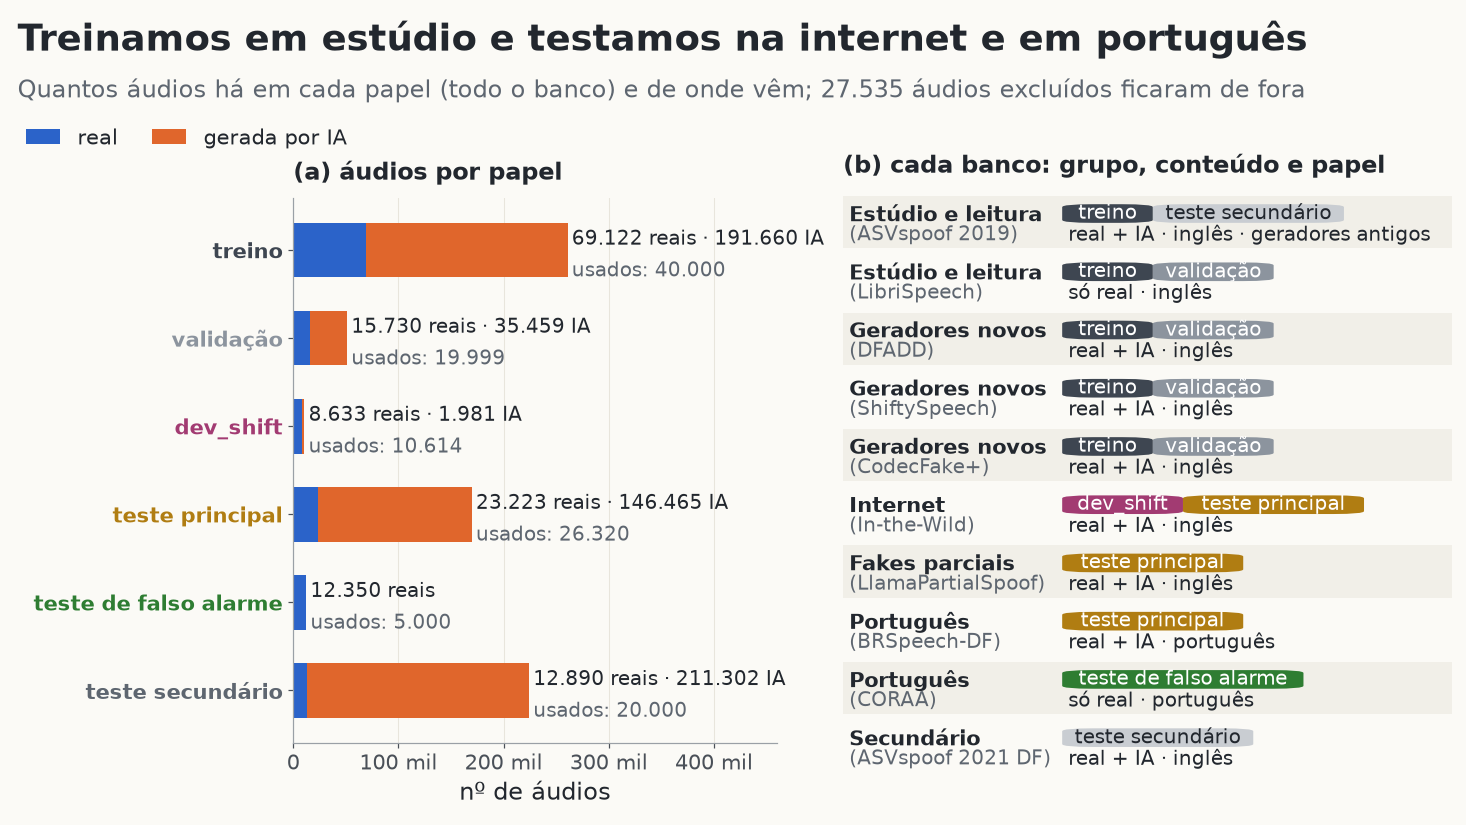

In [3]:
figura("01_composicao_banco")

**O que olhar:** o treino e a validação são grandes e quase todos de inglês de estúdio ou leitura; a internet (dev_shift e In-the-Wild) e o português só aparecem fora do treino; o treino tem muito mais IA que reais (por isso a amostra metade/metade).

**O que concluir:** o sistema aprende num mundo (estúdio, inglês) e é cobrado em outros (internet, fakes parciais, português). A diferença entre esses mundos explica a maior parte dos erros das figuras seguintes.

**O que faz:** mostra a tabela `results/slides/grupos_bancos.csv` (banco, grupo, o que é, real/IA, idioma, ano, papel e nº de áudios) e conta, no manifest, os áudios por banco, divisão e rótulo. **Por quê:** o manifest é a única fonte da verdade sobre os dados; a tabela confirma a divisão acima.

In [4]:
tabela("grupos_bancos.csv", pasta=SLIDES)
df = pd.read_parquet("data/processed/manifest.parquet", columns=["source_dataset", "split", "label", "eval_subset"])
df["split"] = df["split"].fillna("excluído")
df.loc[df.eval_subset == "dev_shift", "split"] = "dev_shift"
t = df.groupby(["source_dataset", "split", "label"]).size().unstack(["split", "label"], fill_value=0)
t.columns = [f"{s}/{'IA' if l else 'real'}" for s, l in t.columns]
display(t[sorted(t.columns)])

,banco,grupo,o que é,real/IA,idioma,ano,geração dos geradores,papel,nº real,nº IA
0,ASVspoof 2019,Estúdio e leitura,"Desafio ASVspoof 2019, acesso lógico: falas do VCTK lidas em estúdio, com lo...",real e IA,inglês,2019 (do nome do banco),antigos (docs/dataset_overview.md: 'os antigos do ASVspoof 2019'),treino,5128,45096
1,CodecFake+,Geradores novos,Amostras de páginas de demonstração de 17 TTS baseados em codec neural (só a...,real e IA,inglês,não documentado,novos (agrupamento do projeto),treino,702,743
2,DFADD,Geradores novos,Falas do VCTK gravadas em estúdio e as mesmas frases geradas por 5 TTS (Grad...,real e IA,inglês,não documentado,novos (agrupamento do projeto),treino,35745,131700
3,LibriSpeech,Estúdio e leitura,Leitura de audiolivros (train-clean-100); só vozes reais.,só real,inglês,não documentado,— (só real),treino,22840,0
4,ShiftySpeech,Geradores novos,Leitura de audiolivro (LibriSpeech) e a mesma fala ressintetizada por 3 voco...,real e IA,inglês,não documentado,novos (agrupamento do projeto),treino,4707,14121
5,CodecFake+,Geradores novos,Amostras de páginas de demonstração de 17 TTS baseados em codec neural (só a...,real e IA,inglês,não documentado,novos (agrupamento do projeto),validação,164,188
6,DFADD,Geradores novos,Falas do VCTK gravadas em estúdio e as mesmas frases geradas por 5 TTS (Grad...,real e IA,inglês,não documentado,novos (agrupamento do projeto),validação,8710,31800
7,LibriSpeech,Estúdio e leitura,Leitura de audiolivros (train-clean-100); só vozes reais.,só real,inglês,não documentado,— (só real),validação,5699,0
8,ShiftySpeech,Geradores novos,Leitura de audiolivro (LibriSpeech) e a mesma fala ressintetizada por 3 voco...,real e IA,inglês,não documentado,novos (agrupamento do projeto),validação,1157,3471
9,In-the-Wild,Internet,"Falas de 54 figuras públicas coletadas na internet, reais e falsas; o gerado...",real e IA,inglês,não documentado,não documentado,dev_shift,8633,1981


,dev_shift/IA,dev_shift/real,excluído/IA,excluído/real,test/IA,test/real,train/IA,train/real,val/IA,val/real
source_dataset,,,,,,,,,,
asvspoof2019_la,0,0,0,838,63882,7355,45096,5128,0,0
asvspoof2021_df,0,0,0,0,147420,5535,0,0,0,0
brspeech_df,0,0,0,0,6587,1320,0,0,0,0
codecfake_plus,0,0,0,0,0,0,743,702,188,164
coraa,0,0,0,326,0,12350,0,0,0,0
dfadd,0,0,0,0,0,0,131700,35745,31800,8710
in_the_wild,1981,8633,0,0,9835,11330,0,0,0,0
librispeech,0,0,0,5323,0,0,0,22840,0,5699
llamapartialspoof,0,0,0,0,130043,10573,0,0,0,0


**Conclusão:** o treino é todo em inglês e quase todo de estúdio ou audiolivro; o dev_shift é o único conjunto "de internet" que podemos usar para decidir. Os áudios realmente usados pelo F0 são uma amostra: 40.000 de treino, 19.999 de validação e o dev_shift inteiro.

## 4. O pipeline do sistema v4, passo a passo

Antes do sistema final, a figura 02 mostra como as versões 1 a 3 viam o áudio (log-mel + CNN). Na v4, essa etapa foi trocada por um modelo de fala pronto.

### Figura 02 · Como o áudio vira imagem (versões 1 a 3)

**O que ela mostra:** a mesma frase, dita pelo mesmo locutor do VCTK: à esquerda a gravação real, à direita a versão gerada por um TTS (validação, 4 s do meio). De cima para baixo: a forma de onda (a pressão do ar ao longo do tempo), o espectrograma (quanta energia há em cada frequência, a cada instante) e o log-mel de 64 faixas (o mesmo, com as frequências agrupadas como o ouvido agrupa e o brilho em escala logarítmica). No espectrograma e no log-mel, o eixo horizontal é o tempo, o vertical é a frequência (graves embaixo, agudos em cima) e o brilho é a intensidade.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/02_log_mel.png`.*

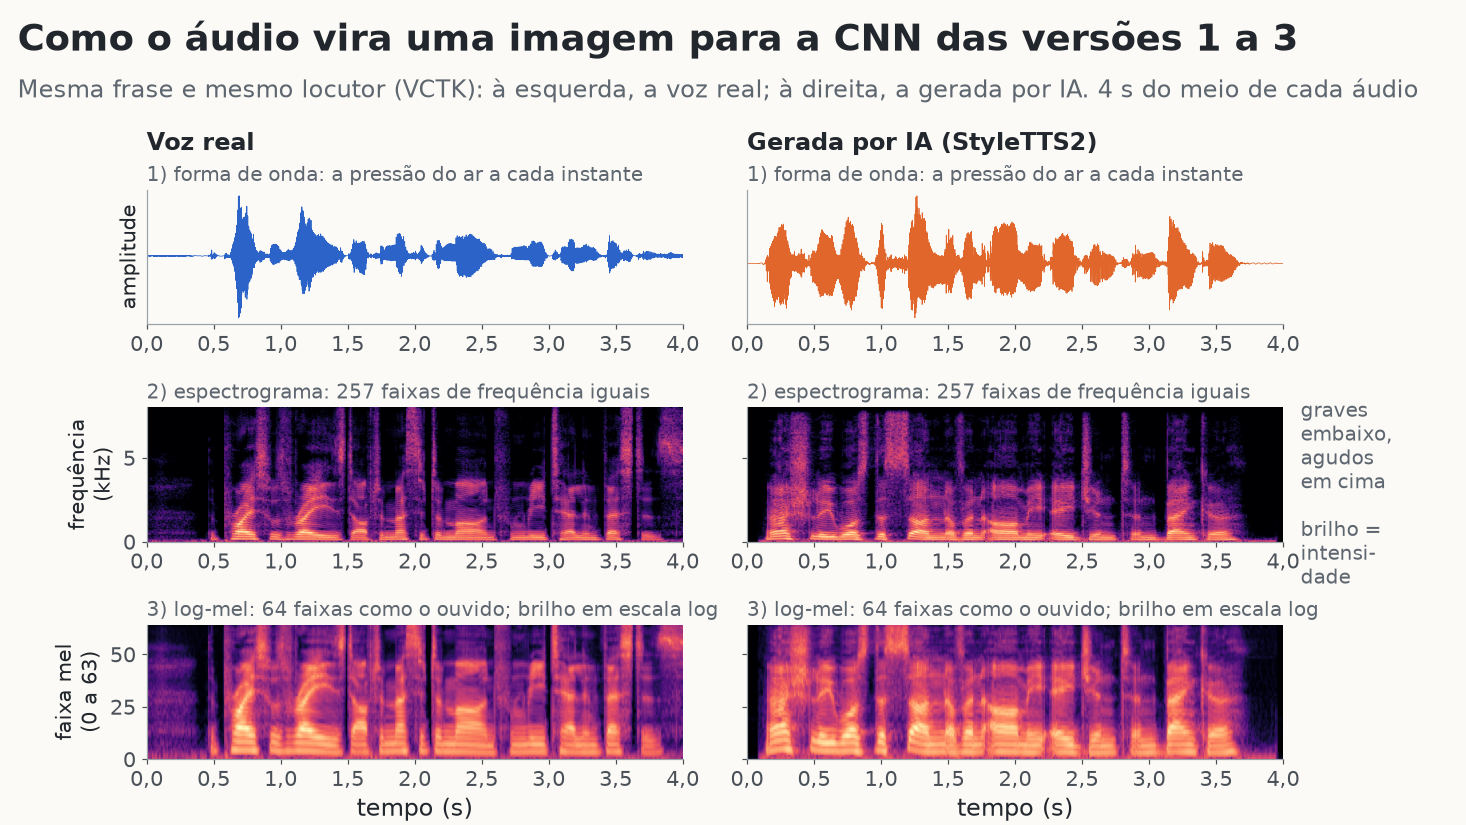

In [5]:
figura("02_log_mel")

**O que olhar:** as duas imagens são parecidas no geral (a mesma frase); as diferenças estão em detalhes finos, como a textura dos agudos e as pausas.

**O que concluir:** a CNN das versões 1 a 3 recebia o log-mel (a imagem de baixo) e tinha de achar sozinha esses detalhes; ela aprendeu bem o estúdio e falhou na internet (seção 9). A partir da v4, a onda vai direto para o XLS-R. A figura é só uma ilustração com 2 áudios, não uma medida.

**O pipeline do F0:**

1. **Áudio → pré-processamento** (`src/preproc.py`): mono, 16 kHz; corte do silêncio nas bordas (quadros 35 dB abaixo do mais forte; se sobrar menos de 0,5 s, não corta); recorte central de no máximo 8 s; **sem completar** (nem repetição nem zeros: cada áudio fica com o seu tamanho). Cada áudio é normalizado (média 0, variância 1). ⚠️ Fora da trilha: o corte de silêncio por energia.
2. **XLS-R 300M da Meta, congelado** (`src/ssl.py`): nenhum peso do modelo é treinado por nós. **O que usamos exatamente:** a classe `Wav2Vec2Model` do pacote `transformers` (na v4 ela era chamada direto; hoje o `AutoModel` escolhe a mesma classe, conferido abaixo). Ela é só o **codificador**: a parte convolucional que lê a onda + 24 camadas transformer. O arquivo de pesos foi salvo como `Wav2Vec2ForPreTraining` (o modelo do pré-treino), mas a parte usada no pré-treino para **adivinhar os trechos escondidos** (o quantizador e as projeções da tarefa contrastiva) **não é carregada nem usada**: nós só lemos os vetores internos. ⚠️ Fora da trilha: o modelo auto-supervisionado e o pacote `transformers`.
3. **Vetores por camada:** o modelo devolve 25 saídas (a entrada do transformer e a saída de cada uma das 24 camadas), cada uma com um vetor de 1.024 números a cada 20 ms.
4. **Média no tempo:** cada saída vira um vetor de 1.024 números pela média só nos quadros válidos (o desvio também fica no cache, mas o F0 não usa).
5. **Escolha das camadas: por que 5, 6 e 7.** Treinamos **uma regressão por camada** (25 regressões), cada uma com o seu C escolhido pela validação, e ordenamos as camadas pela **menor EER média por fonte na validação**: 7, 5, 6, 8, 9… (figura 05). As **três melhores** (5, 6 e 7) foram **concatenadas** (3 × 1.024 = 3.072 números); juntar as quatro melhores também foi testado, e a validação preferiu três. Uma explicação possível (**HIPÓTESE, não provada**): as camadas do meio ainda guardam mais detalhe do som, enquanto a última fica mais perto do que foi dito (as palavras) do que de como o som foi produzido.
6. **Regressão logística** (scikit-learn): a única parte treinada com os nossos rótulos (seção 5).

**Por que o modelo pronto ajudou tanto (EXPLICAÇÃO PROVÁVEL, NÃO PROVADA):** os vetores do modelo pronto vêm de um treino enorme e variado, sem rótulos; os da nossa CNN vinham de um treino estreito e foram moldados só para separar real de IA naquela mistura. Não testamos isso diretamente (por exemplo, não treinamos uma regressão logística sobre os vetores internos da CNN); é a leitura mais provável, não um resultado.

**O que faz:** mostra qual classe o `AutoModel` escolhe para o XLS-R e o que diz o `config.json` em cache (lidos pelo script das figuras, sem carregar os pesos). **Por quê:** confirmar o que de fato é usado, em vez de supor.

In [6]:
if F0:
    display(pd.Series(F0["modelo_hf"], name="valor").to_frame())

,valor
classe_AutoModel_para_wav2vec2,Wav2Vec2Model
config_architectures,[Wav2Vec2ForPreTraining]
config_num_hidden_layers,24
config_hidden_size,1024


**Conclusão:** a classe é `Wav2Vec2Model` (só o codificador), com 24 camadas de 1.024 números, como no código da v4.

### Figura 05 · Quais camadas do modelo separam melhor real de IA?

**O que ela mostra:** para cada uma das 25 saídas do XLS-R (eixo x), uma regressão logística treinada só com aquela camada. À esquerda, o erro (EER: o erro no corte em que reais acusados e IA que passa têm a mesma taxa); à direita, a AUC (a chance de dar nota maior a um áudio de IA que a um real). Linha cinza: estúdio (validação); linha vinho: internet (dev_shift). A faixa verde marca as camadas usadas no sistema (5, 6, 7).

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/05_camadas.png`.*

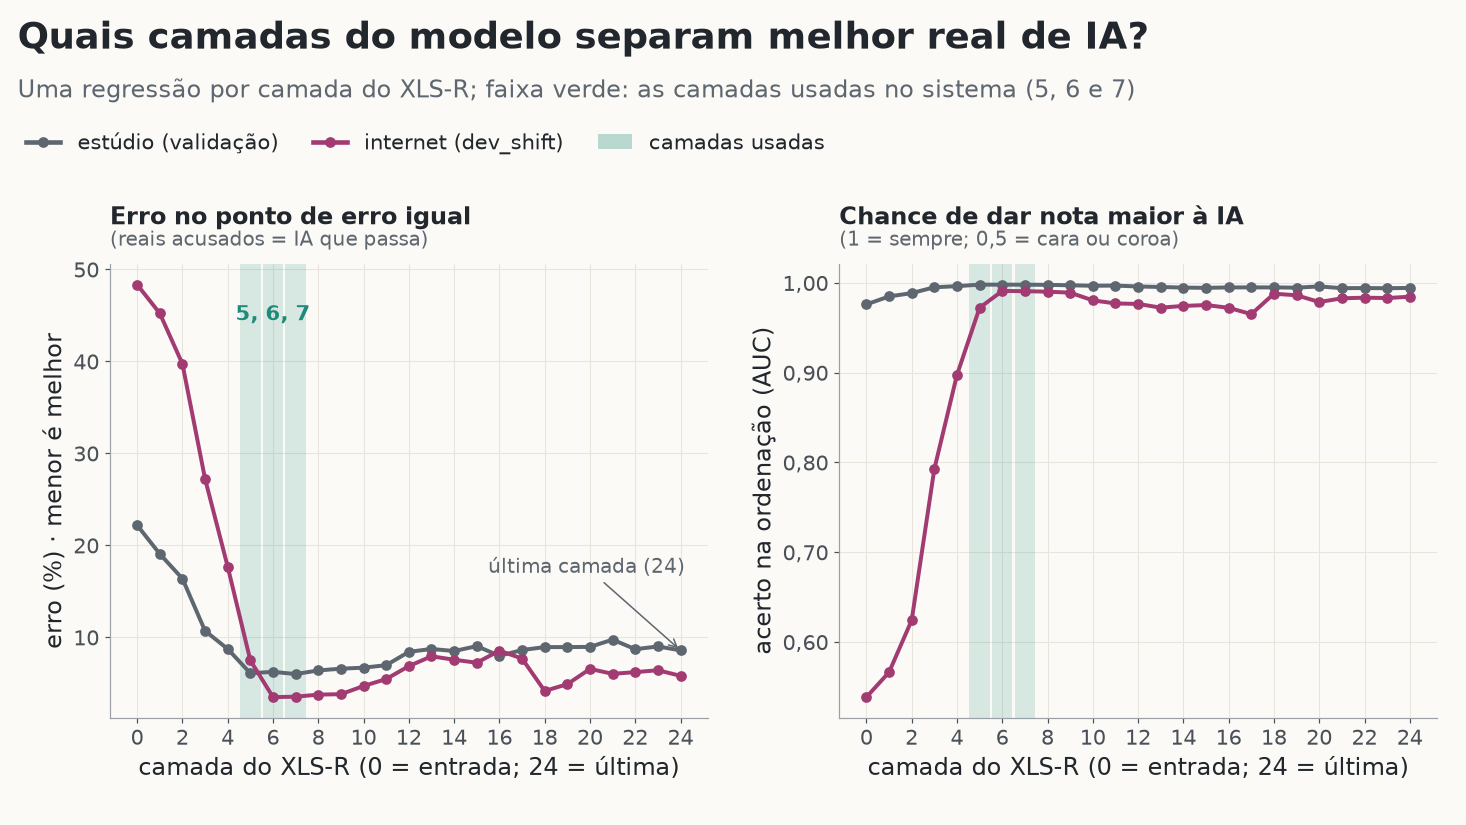

In [7]:
figura("05_camadas")

**O que olhar:** as camadas 0 a 3 quase não servem na internet (AUC 0,54 a 0,79); da 5 em diante, tudo passa de 0,97; as camadas 5 a 7 têm o menor erro no estúdio (a 7 sozinha: 6,0%; a 0: 22%; a 24: 8,6%).

**O que concluir:** as pistas úteis estão nas camadas do meio, e a escolha feita só pela validação caiu na região boa também para a internet; mas a última camada (24) já é quase tão boa na internet, o que bate com o S1 no teste (seção 8). O dev_shift é mostrado aqui, mas não escolheu nada.

### Figura 06 · Os vetores do modelo, sem a regressão

**O que ela mostra:** cada ponto é um áudio, representado pelo vetor de 1.024 números de uma camada do XLS-R, achatado em 2 dimensões por um método que tenta manter perto o que já era parecido (t-SNE; ⚠️ Fora da trilha). Ninguém disse ao método quem é real ou IA: as cores são pintadas depois. Colunas: camadas 5, 6, 7 e 24. Linha 1: só a validação (3.000 áudios), cor real × IA. Linha 2: validação + dev_shift (3.000 + 3.000), cor = origem (estúdio × internet). Linha 3: só o dev_shift (3.000), cor real × IA.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/06_vetores.png`.*

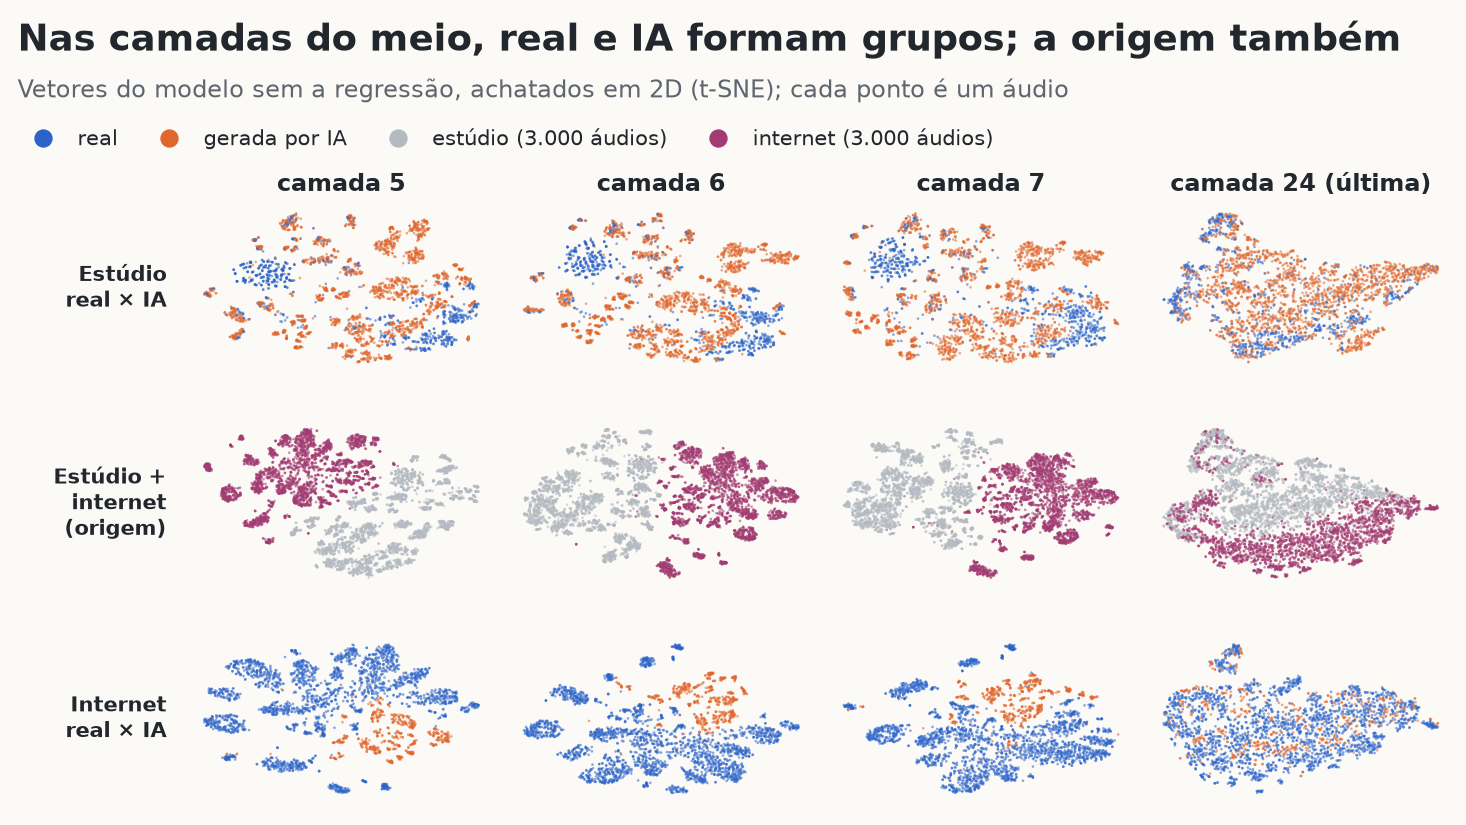

In [8]:
figura("06_vetores")

**O que olhar:** na linha 1 (estúdio), nas camadas 5 a 7 os pontos se juntam em muitos grupinhos de uma cor só; na camada 24, as cores se misturam mais. Na linha 2, estúdio e internet ocupam regiões separadas em **todas** as camadas, inclusive na 24: é a separação mais forte da figura. Na linha 3 (só internet), nas camadas 5 a 7 os gerados por IA se concentram numa região; na 24, ficam espalhados entre os reais.

**O que concluir:** mesmo sem nenhum rótulo, os vetores das camadas do meio já carregam a diferença real × IA, também na internet; a última camada guarda menos dessa diferença (o mesmo que a figura 05 mostra em números). Mas a informação mais forte nos vetores é "de onde veio a gravação", e por isso um corte calibrado só no estúdio não se transfere sem ajuste para a internet (figuras 03 e 04). O t-SNE distorce distâncias: só os agrupamentos têm leitura, não as posições nem os tamanhos.

### G3 · A versão anterior desta análise (PCA e t-SNE, camadas 7 e 24)

**O que ela mostra:** os mesmos 3.000 + 3.000 áudios, nas camadas 7 e 24, com dois métodos de achatar: PCA (as duas direções de maior variação; ⚠️ Fora da trilha) e t-SNE. Cada projeção aparece duas vezes: cor real × IA e cor estúdio × internet.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Só no notebook.*

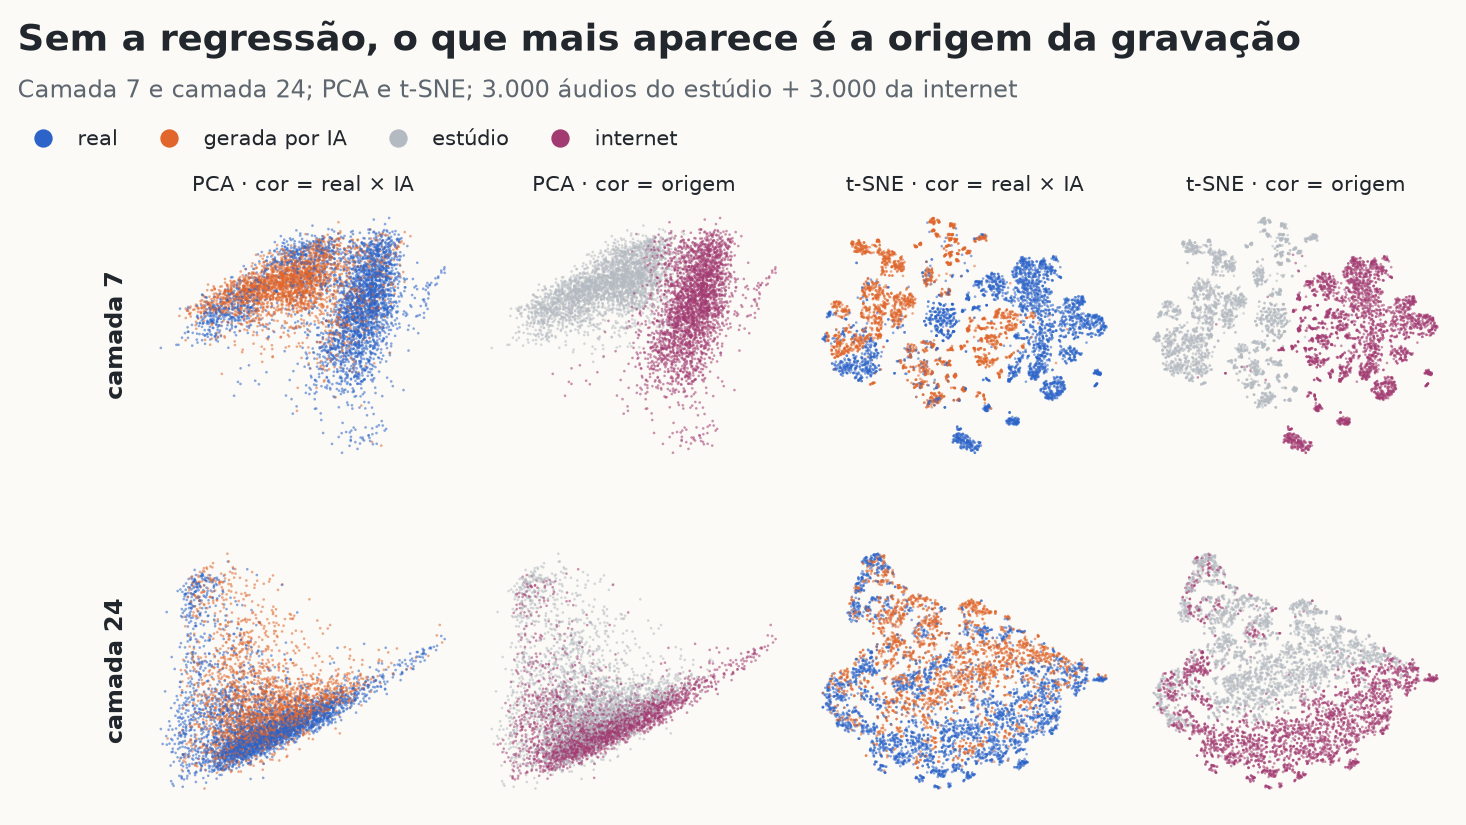

In [9]:
figura("g3_projecao")

**O que olhar:** nas duas camadas, a separação que mais salta aos olhos é estúdio × internet (o tipo de gravação); real × IA aparece em grupos menores, mais claros na camada 7.

**O que concluir:** os vetores do modelo pronto carregam muita informação de "de onde veio a gravação", e a regressão (seção 5) é o que acha a direção real × IA no meio disso; o t-SNE distorce distâncias, então só os agrupamentos (não as posições) têm leitura.

## 5. A NOSSA PARTE: a regressão logística

**O que é, em linguagem simples.** Para cada áudio temos 3.072 números (x). A regressão multiplica cada número por um peso, soma tudo e soma um número fixo: **nota z = w·x + b**. Se a nota passa do **corte**, o áudio é chamado de **gerado por IA**. A nota vira probabilidade pela sigmoide, p = 1 / (1 + e^(−z)). Na figura, isso é uma **fronteira de decisão reta** (um plano, em 3.072 dimensões): de um lado "real", do outro "IA" (Aula de regressão logística e fronteira de decisão).

**O que ela aprende com os nossos rótulos:** só os 3.072 pesos w e o número b (3.073 parâmetros). O XLS-R não muda.

**O que entra:** a média no tempo das saídas **5, 6 e 7** do XLS-R, cada número **padronizado** com a média e o desvio do treino (assim nenhum número pesa mais só por ter escala maior), concatenadas.

**Hiperparâmetros:**
- **C = 0,1**: o inverso da força do "freio" de regularização L2 (Aula 7, overfitting e regularização). C pequeno = freio forte = pesos pequenos. ⚠️ Fora da trilha só o nome do parâmetro no scikit-learn; a ideia é a da aula.
- **Solver lbfgs** (o padrão do scikit-learn), até 1.000 iterações, tolerância 0,0001. ⚠️ Fora da trilha: o lbfgs (a trilha usa descida do gradiente; o problema é o mesmo, e é convexo, então o resultado não depende de seed).
- **Peso das classes: nenhum.** O treino já tem 20.000 reais e 20.000 gerados por IA.

**Como a camada, o C e os cortes foram escolhidos (tudo na v4, antes do teste):**
1. Uma regressão por camada (25), cada uma com C na grade 0,001 / 0,01 / 0,1 / 1, escolhido pela **EER média por fonte na validação** (média da EER do DFADD, do ShiftySpeech e do CodecFake+; o LibriSpeech só tem reais).
2. As camadas foram ordenadas por essa EER: 7, 5, 6, 8, 9… As 3 melhores (5, 6, 7) foram concatenadas e o C foi escolhido de novo pela mesma régua: **C = 0,1** (tabela abaixo).
3. Entre as candidatas (melhor camada sozinha, 3 camadas, 4 camadas, somas ponderadas), venceu a de menor EER média por fonte: `concat_top3`, 5,92%.
4. **Corte A** (calibrado no estúdio) = o ponto de EER da **validação inteira**: nota −0,04 (probabilidade 0,49). **Corte B** (calibrado na internet) = o ponto de EER do **dev_shift**: nota 8,22 (probabilidade 0,9997). Os dois foram declarados antes do teste. O B é muito mais alto porque, nas vozes de internet, os reais recebem notas mais altas que os reais de estúdio (figura 04).

**O que a nota significa:** quanto maior, mais "cara de IA". A probabilidade só é bem calibrada no mundo de estúdio (G8, seção 7): nas vozes de internet, uma nota alta não quer dizer "certamente IA".

**O que faz:** mostra a grade de C da cabeça F0 e a lista de cabeças candidatas da v4. **Por quê:** é a escolha feita pela validação, com os números exatos.

In [10]:
g = ler(R / "v4_parcial" / "concat_3.json")
if g:
    display(Markdown(f"**Grade de C da concatenação das camadas {g['camadas']}** (escolhido: C = {g['C']:g}):"))
    display(pd.DataFrame(g["grade"]).round(4))
else:
    pendente("`results/v4_parcial/concat_3.json` (fica fora do git)")
rs = ler(R / "v4_resumo.json")
display(Markdown(f"**Candidatas da v4 (EER média por fonte na validação):** vencedora `{rs['cabeça_final_pela_validação']}`"))
display(pd.DataFrame(rs["candidatas"]).round(4))
mc = ler(R / "v4_camadas_concluido.json")
display(Markdown(f"Ordem das camadas pela validação: {mc['ordem_camadas_val'][:6]}…; melhor camada sozinha: "
                 f"{mc['melhor_camada']} (C = {mc['melhor_camada_C']:g})."))

**Grade de C da concatenação das camadas [5, 6, 7]** (escolhido: C = 0.1):

,C,val EER média por fonte,iterações,convergiu,segundos
0,0.001,0.0702,47,True,1.8
1,0.010,0.0660,67,True,2.5
2,0.100,0.0592,56,True,2.1
3,1.000,0.0682,35,True,1.3


**Candidatas da v4 (EER média por fonte na validação):** vencedora `concat_top3`

,cabeça,val EER média por fonte
0,concat_top3,0.0592
1,concat_top4,0.0598
2,rl_camada_7,0.0599
3,soma_mlp,0.0638
4,soma_linear,0.0673


Ordem das camadas pela validação: [7, 5, 6, 8, 9, 10]…; melhor camada sozinha: 7 (C = 0.01).

**Conclusão:** C = 0,1 teve a menor EER média por fonte (5,92%) na grade; com C = 1 (freio fraco) a EER subiu para 6,82%, e com C = 0,001 (freio forte) para 7,02%. As diferenças entre as candidatas são pequenas (5,92% a 6,73%).

### Figura 03 · A regressão vista de cima: estúdio × internet

**O que ela mostra:** cada ponto é um áudio. O eixo horizontal é **a própria nota da regressão** (quanto mais à direita, mais ela acha que é IA); o eixo vertical não decide nada: é só a direção em que os áudios mais variam fora da nota, usada para espalhar os pontos (⚠️ Fora da trilha: PCA). Por isso a fronteira de decisão é exatamente uma reta vertical, no corte. As duas retas são o corte A (calibrado no estúdio) e o corte B (calibrado na internet); a faixa entre elas é a região em que os dois cortes discordam. À esquerda, a validação (estúdio); à direita, o dev_shift (internet).

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/03_plano_regressao.png`.*

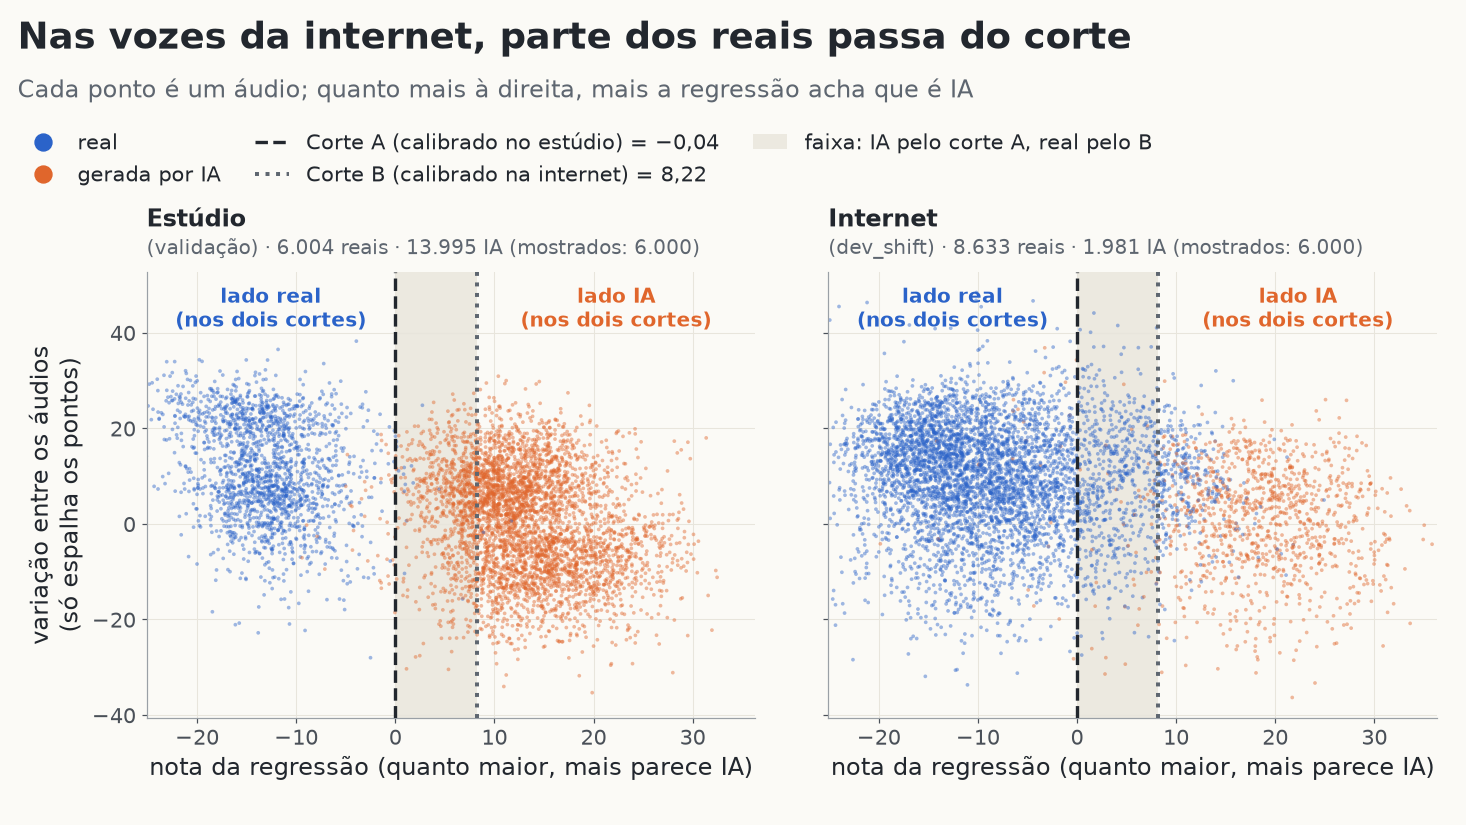

In [11]:
figura("03_plano_regressao")

**O que olhar:** no estúdio, quase todos os reais (azul) ficam à esquerda do corte A e quase todos os gerados por IA (laranja) à direita; na internet, uma **cauda de reais** passa do corte A e cai na faixa do meio.

**O que concluir:** a regressão separa muito bem o mundo do treino; o erro que sobra na internet é de **reais com nota alta**, e é por isso que o corte B (mais à direita) reduz os reais acusados ali. O eixo vertical explica só 11% da variação fora da nota: é uma fatia do espaço, não o espaço inteiro.

### G1 · O mesmo plano, fonte por fonte

**O que ela mostra:** o mesmo desenho da figura 03, com a validação separada por fonte (DFADD, ShiftySpeech, CodecFake+, LibriSpeech), a validação inteira e o dev_shift. Até 6.000 pontos por painel.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Só no notebook.*

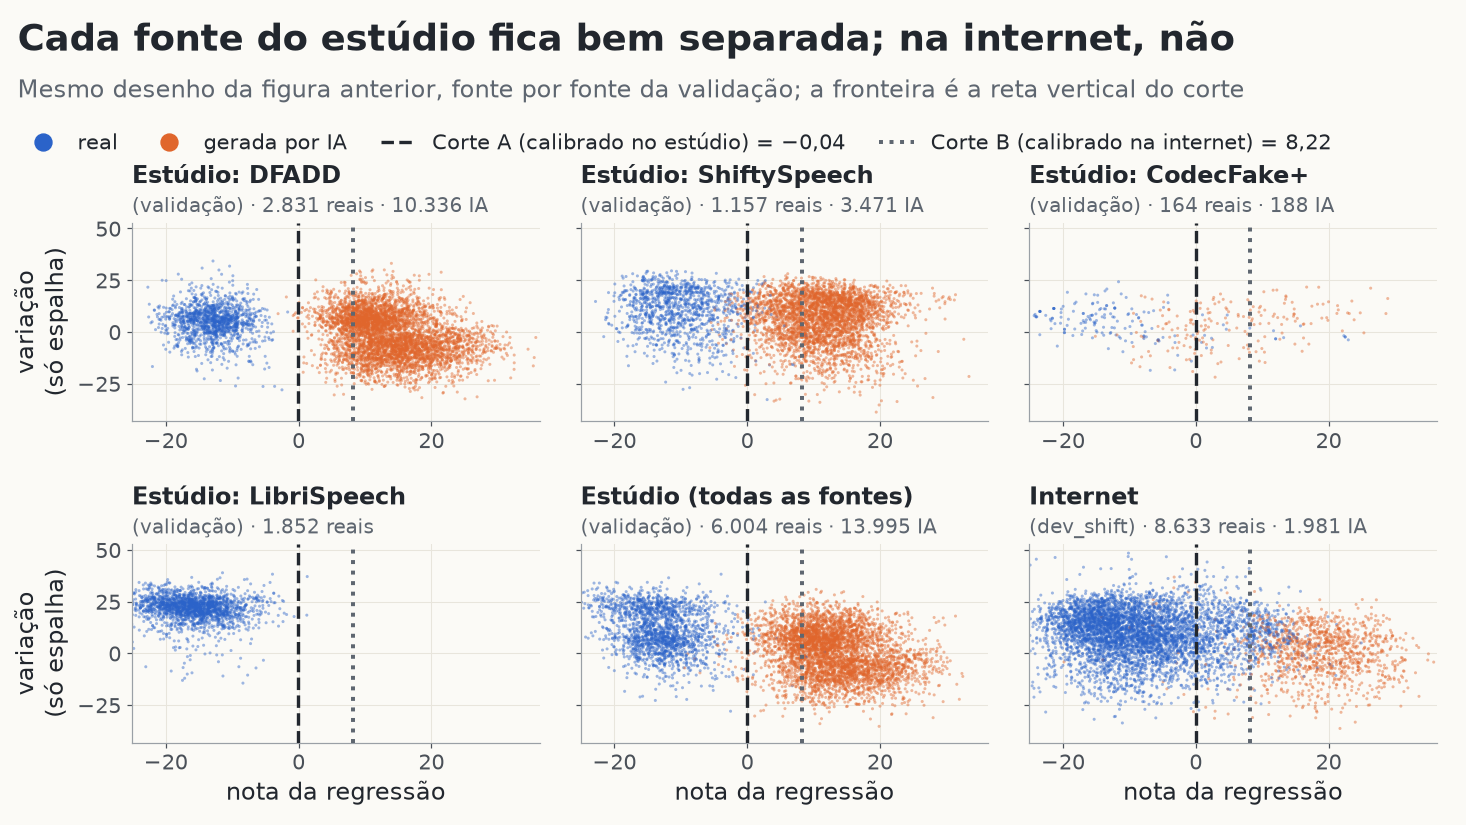

In [12]:
figura("g1_plano_decisao")

**O que olhar:** no DFADD e no LibriSpeech os reais ficam todos à esquerda do corte A; no CodecFake+ (352 áudios) há gerados por IA dos dois lados; no dev_shift, a cauda de reais passa do corte A.

**O que concluir:** dentro do estúdio, a fonte mais difícil é a de codec neural (CodecFake+); fora dele, o problema muda de lado: não são gerados por IA escapando, são reais acusados.

### Figura 04 · Onde caem as notas de reais e de gerados por IA, por grupo

**O que ela mostra:** para cada grupo, dois histogramas da nota: azul para os reais e laranja para os gerados por IA (a altura é a proporção dos áudios daquela classe em cada faixa de nota, então as duas classes são comparáveis mesmo com tamanhos diferentes). As retas A e B são os dois cortes. Grupos: estúdio (validação), internet (dev_shift e teste In-the-Wild), fakes parciais (LlamaPartialSpoof), português (BRSpeech-DF) e português só real (CORAA). Os bancos de teste aparecem só para mostrar: nada foi escolhido com eles.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/04_distribuicao_nota.png`.*

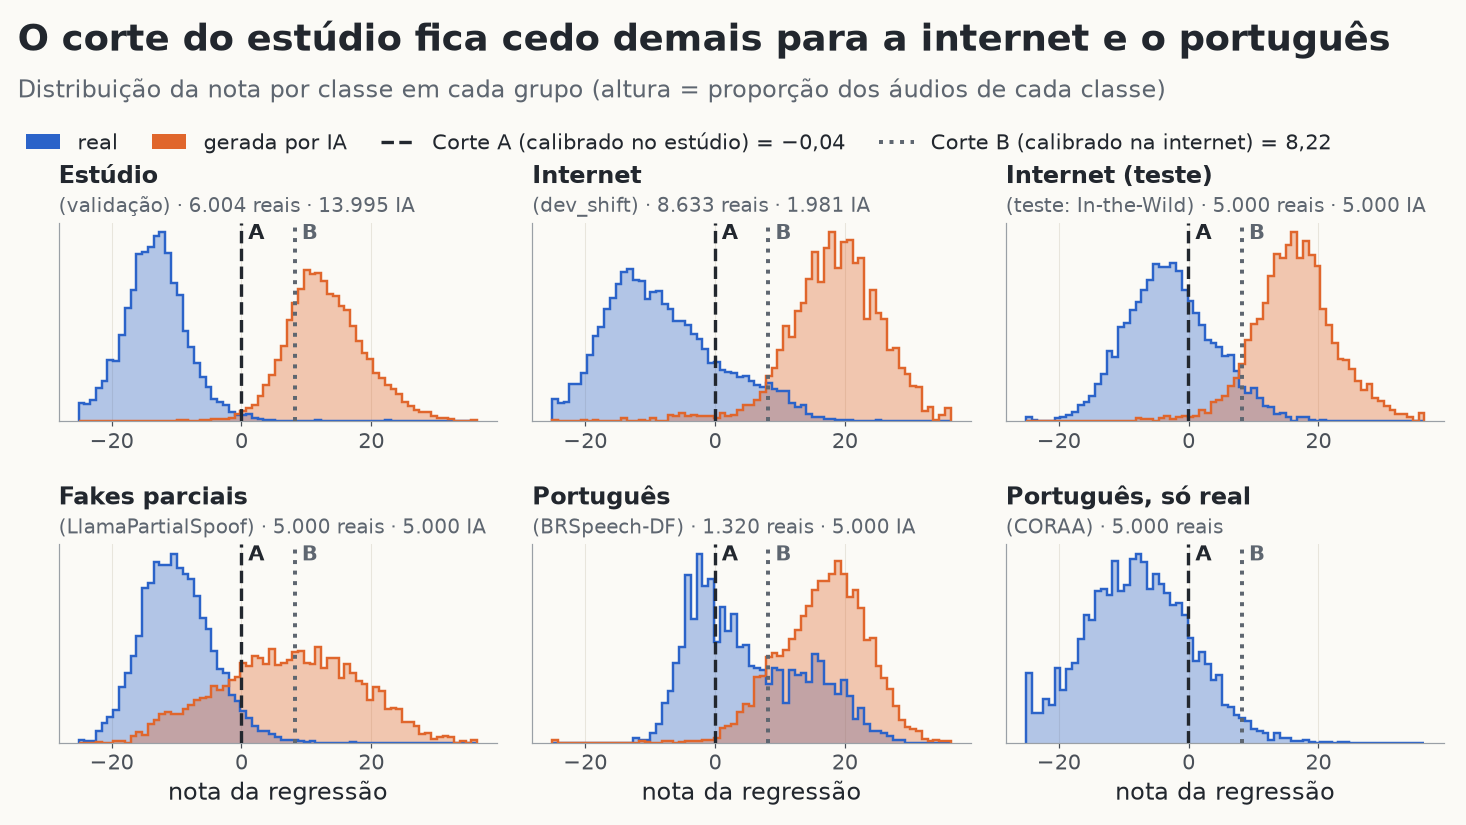

In [13]:
figura("04_distribuicao_nota")

**O que olhar:** a distância entre as duas montanhas e onde ficam os cortes; no estúdio elas quase não se tocam; na internet os reais se deslocam para a direita; no português (BRSpeech-DF) os reais têm duas montanhas, uma delas no meio dos gerados por IA; nos fakes parciais, parte dos gerados por IA fica à esquerda do corte B.

**O que concluir:** o corte A (estúdio) fica cedo demais para a internet e para o português, o que produz reais acusados; o corte B corrige parte disso, mas deixa passar mais gerados por IA (fakes parciais). Por que parte dos reais do BRSpeech-DF tem nota alta **não foi investigado** (o banco mistura pt-BR e pt-PT; é uma hipótese, não um achado).

### G5 · Quanto cada camada pesa dentro da regressão

**O que ela mostra:** a soma dos valores absolutos dos 1.024 pesos de cada camada na regressão final (as entradas são padronizadas, então os pesos são comparáveis) e a distribuição dos pesos dentro de cada camada.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Só no notebook.*

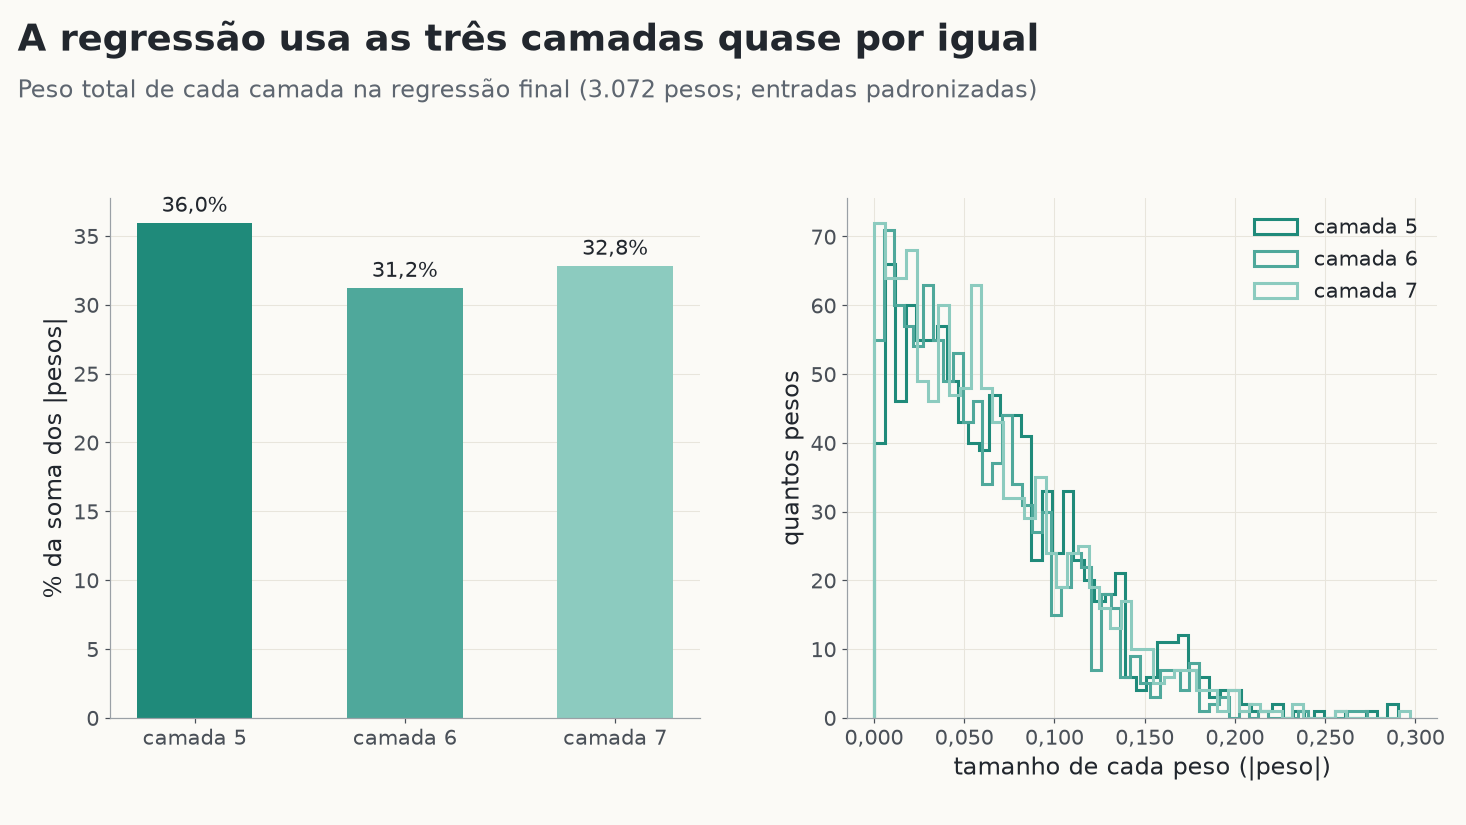

In [14]:
figura("g5_pesos_camadas")

**O que olhar:** as três barras são parecidas (36%, 31% e 33%) e as distribuições dos pesos se sobrepõem.

**O que concluir:** a regressão usa as três camadas quase por igual, sem uma dominar; como as camadas vizinhas são muito parecidas, o peso de cada uma não diz o quanto ela é "necessária" (tirar uma provavelmente mudaria pouco, mas isso não foi testado aqui).

## 6. Por que a regressão logística foi a melhor opção

**(a) Nos nossos testes, as cabeças mais complexas não ganharam.**
- **v4** (regra: menor EER média por fonte na validação): regressão em 1 camada 5,99%, em 3 camadas 5,92%, em 4 camadas 5,98%, soma ponderada + linear 6,63% a 6,85% (3 seeds), soma ponderada + MLP 6,28% a 6,57%. A vencedora foi uma regressão logística. As diferenças entre as regressões (0,06 ponto) são muito menores que a régua de ruído que a v3 mediu na validação (1,5 ponto na EER média por fonte, entre seeds da CNN); **não fizemos teste formal de ruído na v4**, então "empate" aqui é leitura, não prova.
- **v6, E4** (regra do desafiante: uma cabeça mais complexa só entra com diferença relevante, IC95 sem o zero e ≥ 0,005 na AUC da pior fonte, nas 3 seeds): RL 0,904; MLP 0,902 a 0,912; CNN 0,906 a 0,910. **Nenhuma seed de MLP ou CNN teve diferença relevante** → fica a RL, a mais simples.
- Pelas duas regras (menor erro na v4; desafiante na v6), a cabeça que fica é uma regressão logística. Atenção: a RL da E4 era a camada 11 com C = 1 (não o F0); o F0 entra na tabela como referência.

**(b) Menos parâmetros, menos risco de overfitting (Aula 7) e treino em segundos:** RL 3.073 parâmetros (F0) contra 262.657 (MLP) e 405.825 (CNN) da E4; o F0 treina em ~2 s no processador.

**(c) Da literatura (NÃO VERIFICADO POR NÓS; informado pela pesquisa de apoio do projeto, que não reproduzimos):** num artigo da Interspeech 2024 sobre o XLS-R 2B congelado, a regressão logística teve EER médio de 6,5%, contra 8,2% do MLP e 11,3% da autoatenção. Não lemos o artigo nesta sessão nem reproduzimos esses números.

**(d) Controle com rótulos embaralhados (um teste de sanidade).** Treinamos a mesma regressão (camada 7, C = 0,01) com os rótulos do treino **embaralhados ao acaso**, de modo que "real" e "IA" deixam de ter qualquer relação com o som. Se mesmo assim ela acertasse, haveria um problema no procedimento (por exemplo, a avaliação vazando informação do rótulo, ou um erro de código). Resultado: AUC 0,474 na validação e 0,486 no dev_shift, ou seja, **cara ou coroa** (0,5), como deveria. A regressão não "inventa" separação: o que ela acerta vem do som.

**(e) Por que MLP e CNN não ganham (HIPÓTESE, não provada).** Os vetores das camadas do meio do XLS-R já separam real e IA quase com uma reta (figuras 03 e 06), então uma fronteira curva tem pouco a acrescentar. E, com 40.000 áudios de um só mundo (estúdio), mais parâmetros podem decorar detalhes do estúdio que não valem na internet: a própria regressão já acerta 100% do treino (figura 08). As figuras 07 e 08 mostram o mesmo tema por outro lado: mais freio e mais simplicidade não pioraram a internet.

**O que NÃO foi provado:** que a RL seja melhor que MLP ou CNN (só que não perdeu de forma demonstrável); que as 3 camadas sejam melhores que a última sozinha no teste (S2 − S1 "não demonstrada", seção 8); que o C = 0,1 seja o melhor fora do estúdio (a figura 07 sugere o contrário).

**O que faz:** mostra as tabelas das cabeças da v4 e da E4 da v6 e o resultado do controle embaralhado, lidos do disco. **Por quê:** os números da comparação, sem resumo.

In [15]:
display(Markdown("**v4: cabeças sobre o XLS-R (escolha pela EER média por fonte na validação; dev_shift só reportado)**"))
tabela("v4final_cabecas_v4.csv", 4)
display(Markdown("**v6, E4: RL × MLP × CNN (AUC da pior fonte = menor AUC entre DFADD, ShiftySpeech, CodecFake+ e dev_shift)**"))
tabela("v4final_cabecas_v6_e4.csv", 4)
at = ler(R / "v4_atalhos.json")
display(Markdown("**Controle com rótulos embaralhados (v4):**"))
display(pd.Series(at["d_controle_rotulos_embaralhados"]).round(3).to_frame("valor"))

**v4: cabeças sobre o XLS-R (escolha pela EER média por fonte na validação; dev_shift só reportado)**

,rodada,cabeça,tipo,seed,camadas,camada,C,val EER média por fonte,dev AUC,dev EER,dev acurácia balanceada
0,v4 (regra: menor EER média por fonte na validação),rl_camada_7,"regressão logística, melhor camada",-,NaN,7.0,0.01,0.0599,0.9907,0.0353,0.9350
1,v4 (regra: menor EER média por fonte na validação),concat_top3,"regressão logística, concatenação ([5, 6, 7])",-,"[5, 6, 7]",NaN,0.10,0.0592,0.9833,0.0588,0.8965
2,v4 (regra: menor EER média por fonte na validação),concat_top4,"regressão logística, concatenação ([5, 6, 7, 8])",-,"[5, 6, 7, 8]",NaN,0.01,0.0598,0.9896,0.0405,0.9170
3,v4 (regra: menor EER média por fonte na validação),soma_linear,soma ponderada + linear,42,NaN,NaN,NaN,0.0663,0.9828,0.0480,0.9109
4,v4 (regra: menor EER média por fonte na validação),soma_linear,soma ponderada + linear,123,NaN,NaN,NaN,0.0685,0.9822,0.0492,0.9073
5,v4 (regra: menor EER média por fonte na validação),soma_linear,soma ponderada + linear,2026,NaN,NaN,NaN,0.0671,0.9816,0.0495,0.9000
6,v4 (regra: menor EER média por fonte na validação),soma_linear_ensemble,"soma ponderada + linear (ensemble, só reportado)",média das 3,NaN,NaN,NaN,0.0700,0.9822,0.0490,0.9056
7,v4 (regra: menor EER média por fonte na validação),soma_mlp,soma ponderada + MLP,42,NaN,NaN,NaN,0.0657,0.9821,0.0631,0.8722
8,v4 (regra: menor EER média por fonte na validação),soma_mlp,soma ponderada + MLP,123,NaN,NaN,NaN,0.0629,0.9863,0.0521,0.8787
9,v4 (regra: menor EER média por fonte na validação),soma_mlp,soma ponderada + MLP,2026,NaN,NaN,NaN,0.0628,0.9830,0.0541,0.9111


**v6, E4: RL × MLP × CNN (AUC da pior fonte = menor AUC entre DFADD, ShiftySpeech, CodecFake+ e dev_shift)**

,rodada,sistema,cabeça,seed,parâmetros,segundos,AUC pior fonte,fonte pior,AUC codecfake_plus,AUC dev_shift,val EER média por fonte (3)
0,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,RL básica,RL,-,1025.0,2.2000,0.9037,codecfake_plus,0.9037,0.9719,0.0763
1,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,MLP básico s42,MLP,42,262657.0,2.3000,0.9116,codecfake_plus,0.9116,0.9853,0.0721
2,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,MLP básico s123,MLP,123,262657.0,1.5000,0.9056,codecfake_plus,0.9056,0.9886,0.0755
3,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,MLP básico s2026,MLP,2026,262657.0,1.7000,0.9022,codecfake_plus,0.9022,0.9808,0.0728
4,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,"MLP básico (média das 3 seeds, só reportado)",MLP,média,262657.0,1.8333,0.9065,NaN,0.9065,0.9849,0.0735
5,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,CNN básico s42,CNN,42,405825.0,15.9000,0.9062,codecfake_plus,0.9062,0.9786,0.0625
6,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,CNN básico s123,CNN,123,405825.0,10.1000,0.9081,codecfake_plus,0.9081,0.9828,0.0641
7,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,CNN básico s2026,CNN,2026,405825.0,13.9000,0.9104,codecfake_plus,0.9104,0.9792,0.0609
8,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,"CNN básico (média das 3 seeds, só reportado)",CNN,média,405825.0,13.3000,0.9082,NaN,0.9082,0.9802,0.0625
9,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,"v4 (referência: XLS-R concat 5,6,7 + RL, C=0,1)",RL,-,NaN,NaN,0.9031,codecfake_plus,0.9031,0.9833,0.0592


**Controle com rótulos embaralhados (v4):**

,valor
camada,7.000
C,0.010
val AUC,0.474
val EER média por fonte,0.507
dev AUC,0.486
dev EER,0.505


**Conclusão:** em duas rodadas e com duas regras diferentes, a regressão logística ficou; MLP e CNN tiveram números parecidos com 100 vezes mais parâmetros, e o controle embaralhado deu cara ou coroa, como deveria.

As duas figuras abaixo são **diagnósticos feitos depois** (no documento final): as regressões extras só servem para os gráficos e não mudaram camada, C nem corte.

### Figura 07 · O freio da regressão (C)

**O que ela mostra:** a mesma regressão do sistema treinada com 11 valores de C, do freio mais forte (C = 0,0001, à esquerda) ao mais fraco (C = 10, à direita). À esquerda, o erro (EER) no estúdio e na internet; à direita, o tamanho dos pesos. A faixa verde marca o C usado no sistema (0,1), escolhido na v4 pela validação.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/07_c_freio.png`.*

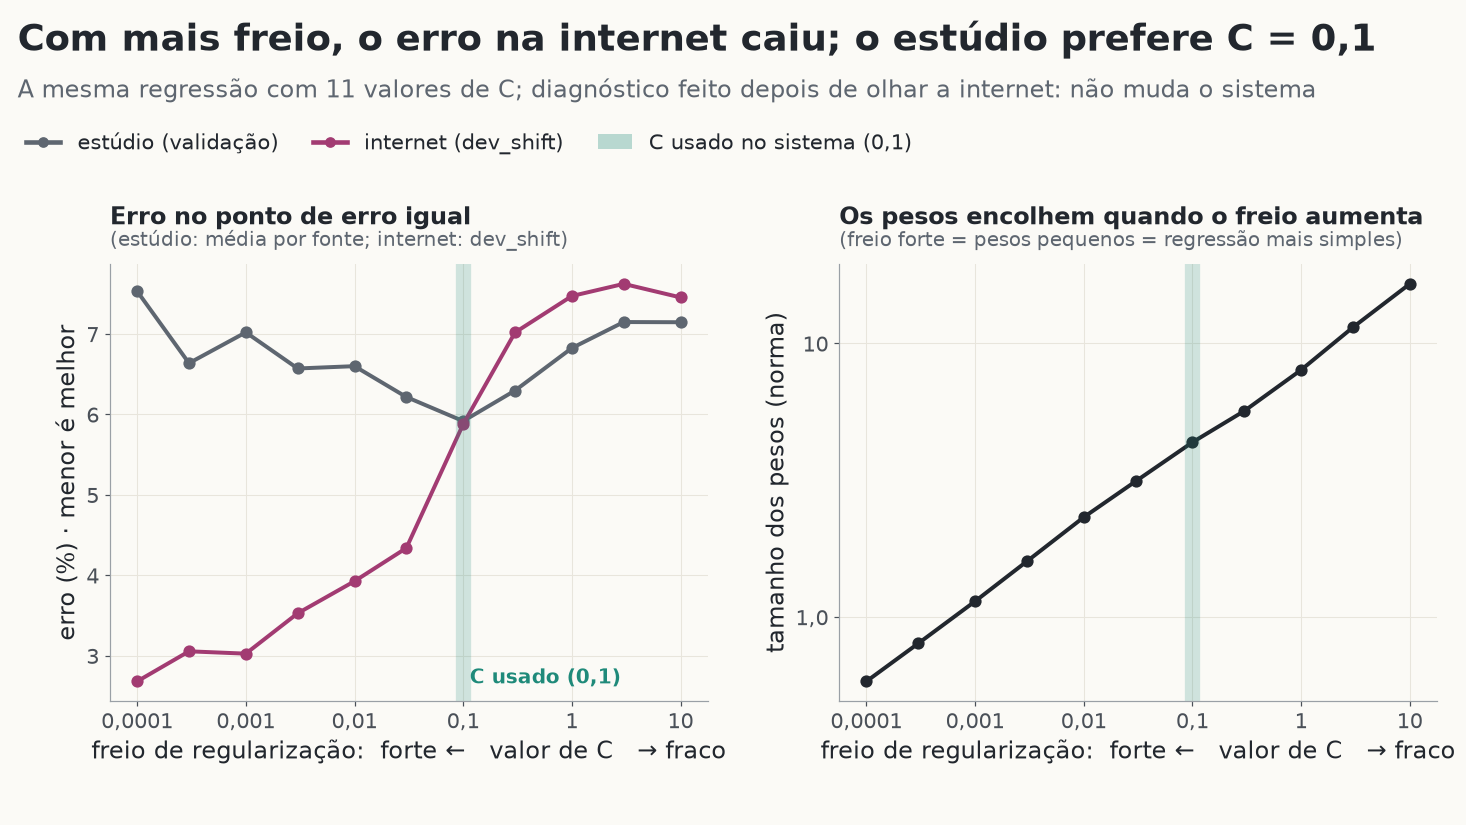

In [16]:
figura("07_c_freio")

**O que olhar:** no estúdio o menor erro fica no C usado (0,1; 5,92%); na internet o erro cai sem parar quando o freio aumenta (C = 0,0001: 2,7%, contra 5,9% no sistema); os pesos encolhem cerca de 30 vezes do freio mais fraco ao mais forte.

**O que concluir:** um freio mais forte (regressão mais simples) parece generalizar melhor para fora do estúdio; é o mesmo tema da v6, em que C = 1 piorou o português. Isto foi visto **depois de olhar o dev_shift** (16 locutores): **não muda o F0** e só vale como hipótese para uma versão nova, confirmada num banco nunca visto.

### Figura 08 · Mais áudios de treino ajudam?

**O que ela mostra:** a mesma regressão (C = 0,1) treinada com 2 mil, 5 mil, 10 mil, 20 mil e 40 mil áudios (metade real, metade IA, um sorteio por tamanho, seed 42). À esquerda, a acurácia balanceada (no corte A de cada modelo); à direita, a AUC; nas duas, no próprio treino (tracejado), no estúdio e na internet.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/08_curva_aprendizado.png`.*

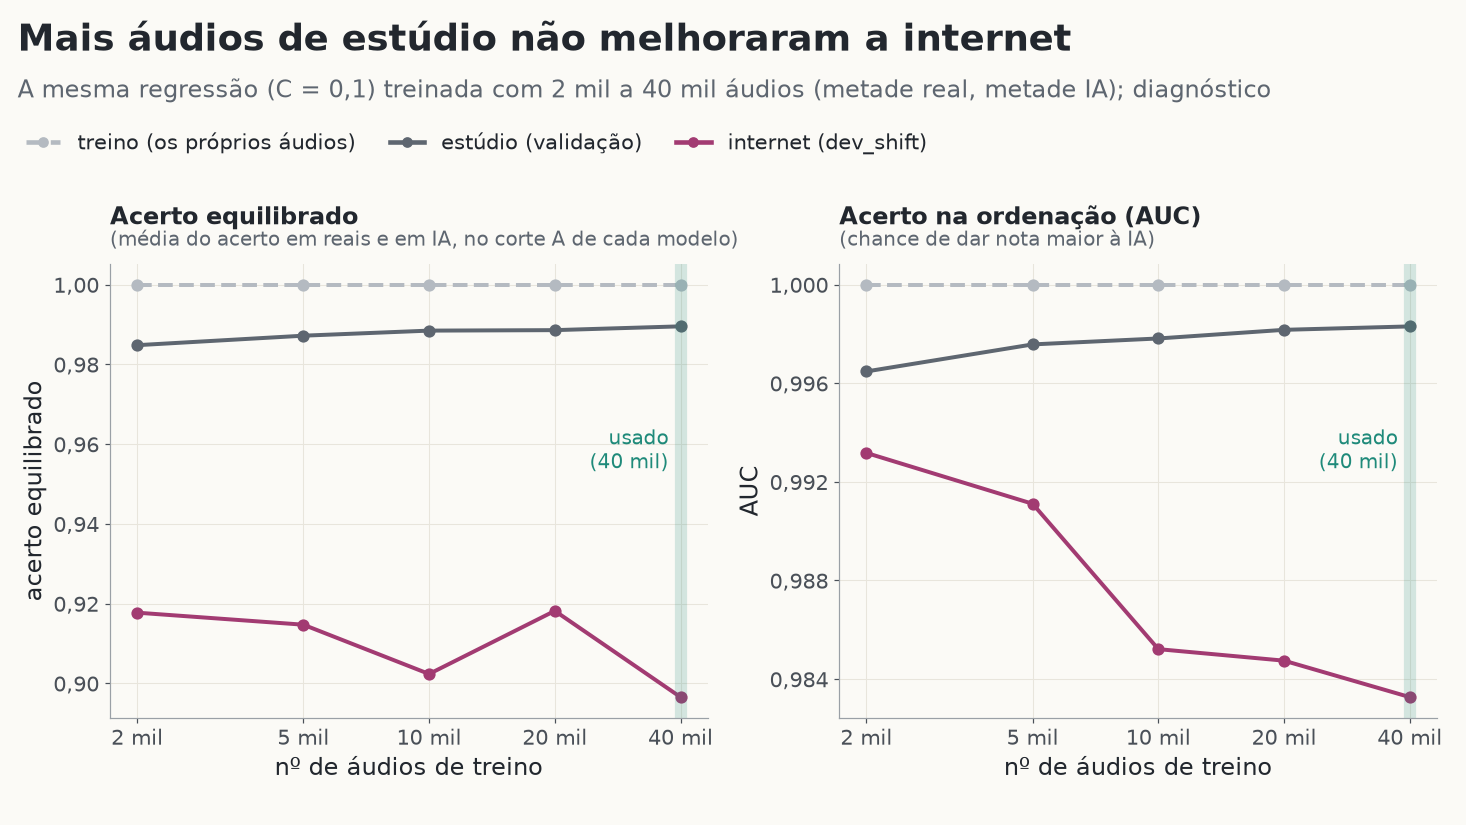

In [17]:
figura("08_curva_aprendizado")

**O que olhar:** o treino fica em 100% em todos os tamanhos; o estúdio sobe devagar (AUC 0,996 → 0,998); a internet **não sobe**: a AUC cai de 0,993 (2 mil) para 0,983 (40 mil).

**O que concluir:** mais áudios do mesmo mundo (estúdio) ajudam o estúdio, mas não a internet; acertar 100% do próprio treino mostra que a regressão consegue decorar o treino (overfitting, Aula 7). É um sorteio por tamanho, sem repetição, então a ordem exata dos pontos pode ser acaso.

## 7. Conferências e diagnósticos

Todas as figuras vêm de `scripts/v4final_figuras.py`, que **reajustou o F0** (mesmos dados, camadas e C; lbfgs é determinístico) e conferiu contra as notas gravadas na v4 antes de desenhar. Os bancos de teste aparecem só para **mostrar**: a regressão e os cortes foram fixados antes do teste.

**O que faz:** mostra a conferência da reprodução (AUC com 3 casas e diferença máxima de nota, por conjunto). **Por quê:** se o reajuste não reproduzisse a v4, os gráficos seriam de outro modelo.

In [18]:
tabela("v4final_reproducao.csv", 6)

,conjunto,n,dif. máx. de nota (logit),AUC reajuste,AUC gravada (v4)
0,val,19999,0.000000,0.998,0.998
1,dev_shift,10614,0.000008,0.983,0.983
2,in_the_wild,10000,0.000010,0.979,0.979
3,llamapartialspoof,10000,0.000007,0.925,0.925
4,brspeech_df,6320,0.000008,0.842,0.842
5,coraa,5000,0.000002,NaN,NaN
6,asvspoof2019_la,10000,0.000007,0.999,0.999
7,asvspoof2021_df,10000,0.000010,0.997,0.997


**Conclusão:** a AUC bate nas 3 casas em todos os bancos e a maior diferença de nota é de ~0,00001 (as notas gravadas estão em float32): os gráficos são do F0 de verdade.

### G8 · A nota como probabilidade

**O que ela mostra:** os áudios agrupados pela probabilidade prevista de ser IA (0 a 0,1, 0,1 a 0,2…); para cada faixa, a fração que é de fato gerada por IA. Os números são os áudios de cada faixa (só faixas com pelo menos 100). Na diagonal, a probabilidade seria perfeita. ⚠️ Fora da trilha: calibração.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Só no notebook.*

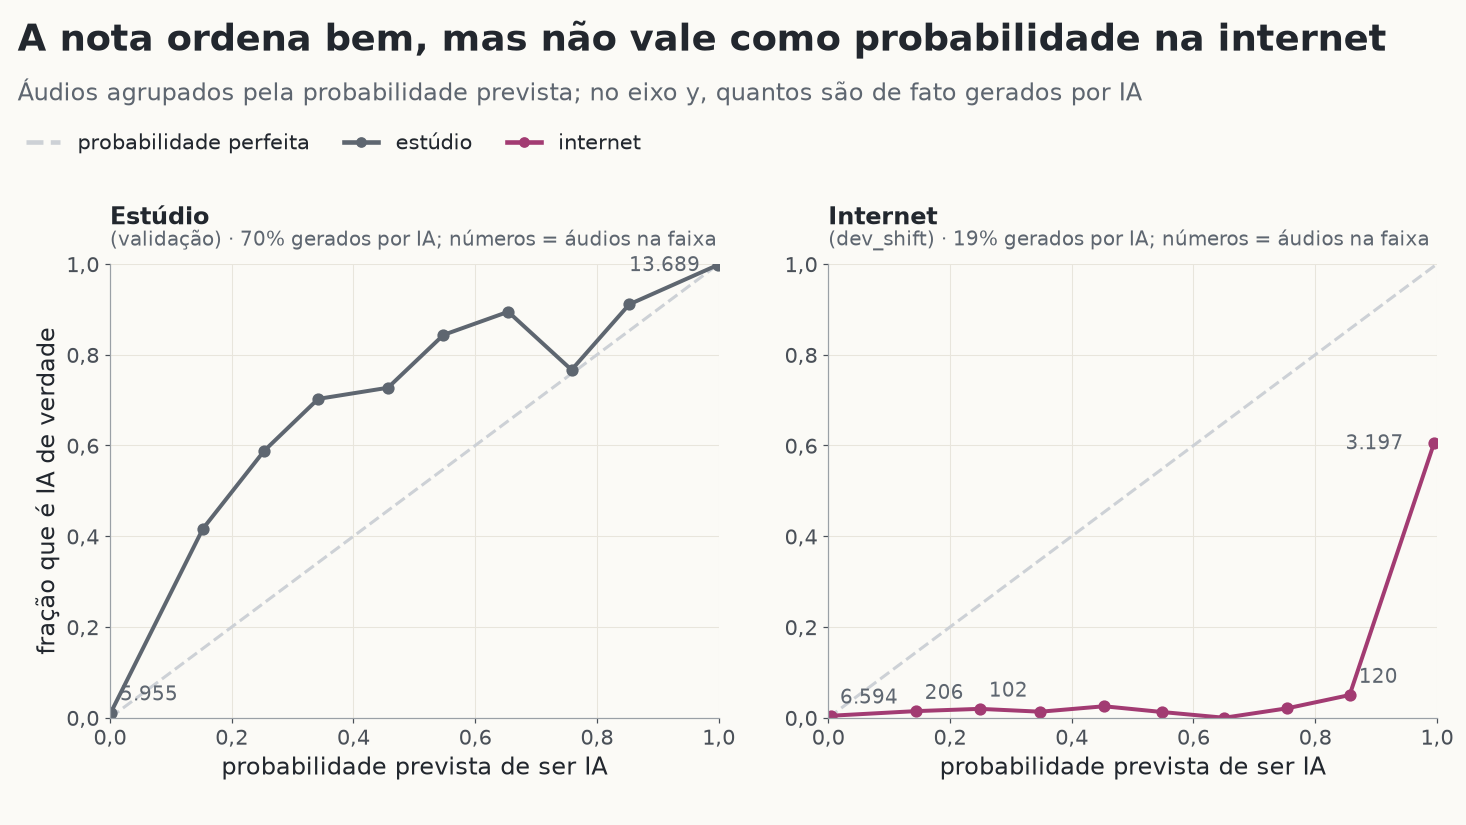

In [19]:
figura("g8_calibracao")

**O que olhar:** no estúdio quase todos os áudios estão nas pontas (0 a 0,1 e 0,9 a 1); na internet, entre 0,1 e 0,9 quase nada é IA, e na faixa 0,9 a 1 só 61% é IA.

**O que concluir:** a nota **ordena** bem, mas não deve ser lida como "chance de ser IA" fora do estúdio: na internet, "99% IA" está errado 4 em cada 10 vezes; a proporção de gerados por IA também muda entre os conjuntos (70% no estúdio, 19% na internet), e a calibração depende dela.

### G13 · Quais geradores escapam na validação

**O que ela mostra:** a % dos gerados por IA detectados, gerador por gerador, na validação (barra: corte A; traço: corte B). No CodecFake+, cada gerador tem de 5 a 32 áudios.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Só no notebook.*

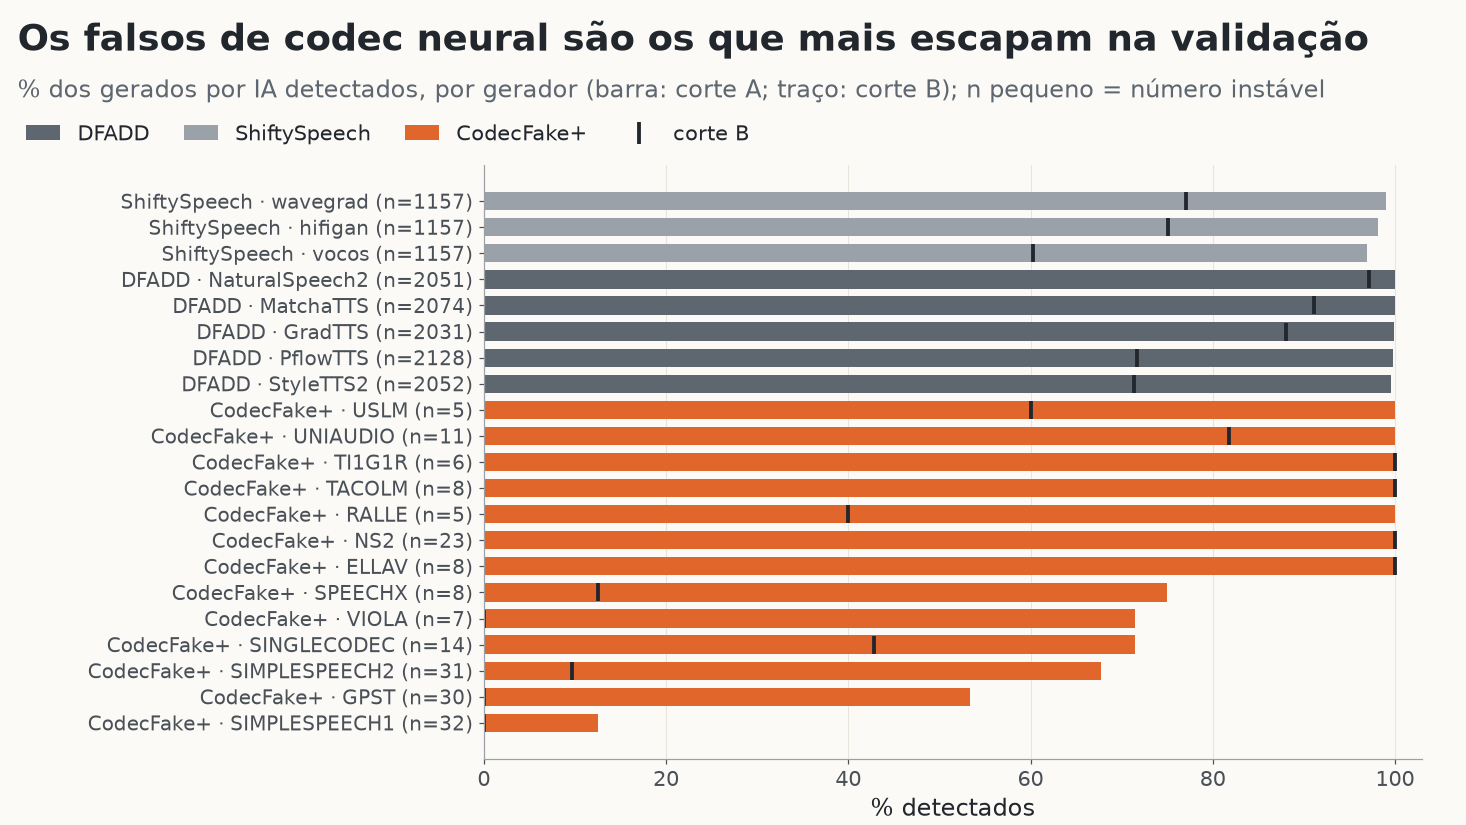

In [20]:
figura("g13_geradores")

**O que olhar:** DFADD e ShiftySpeech ficam perto de 100% no corte A; no CodecFake+ alguns geradores escapam muito (SIMPLESPEECH1 12%, GPST 53%, SIMPLESPEECH2 68%).

**O que concluir:** os gerados por codec neural são o tipo mais difícil dentro da validação; com tão poucos áudios por gerador, os números são instáveis e servem de pista, não de ranking.

## 8. Resultados no teste (F0)

O teste foi avaliado **uma única vez**, na v4 (2026-11-10), pelo pré-registro, com até 5.000 áudios por classe e banco (seed 42); nada foi reescolhido depois. Os números abaixo são os gravados (`results/v4_teste_final.csv`) e o reajuste os reproduz (seção 7).

**O que faz:** tabela por banco com acurácia, acurácia balanceada, acurácia trivial, AUC, EER, recall de IA e falso alarme, nos cortes A e B, para o F0 (e, para comparar, S1 = só a camada 24 e S0 = a CNN da v3). **Por quê:** é o resultado final do sistema.

In [21]:
t8 = pd.read_csv(R / "v4final_teste_por_banco.csv")
cols = ["banco", "limiar", "acurácia", "acurácia balanceada", "acurácia trivial", "AUC", "EER", "recall fake",
        "falso alarme real", "acurácia balanceada IC95", "AUC IC95", "n real", "n fake"]
for s in ("F0 (v4 final)", "S1 (só camada 24)", "S0 (CNN da v3)"):
    display(Markdown(f"**{s}**"))
    display(t8[t8.sistema == s][cols].round(3))

**F0 (v4 final)**

,banco,limiar,acurácia,acurácia balanceada,acurácia trivial,AUC,EER,recall fake,falso alarme real,acurácia balanceada IC95,AUC IC95,n real,n fake
0,in_the_wild,A,0.836,0.835,0.500,0.979,0.068,0.989,0.318,0.829 a 0.842,0.976 a 0.981,5000,5000
1,in_the_wild,B,0.931,0.931,0.500,0.979,0.068,0.920,0.059,0.925 a 0.936,0.976 a 0.981,5000,5000
2,llamapartialspoof,A,0.855,0.855,0.500,0.925,0.147,0.750,0.040,0.849 a 0.862,0.920 a 0.930,5000,5000
3,llamapartialspoof,B,0.738,0.738,0.500,0.925,0.147,0.479,0.002,0.732 a 0.746,0.920 a 0.930,5000,5000
4,brspeech_df,A,0.863,0.679,0.791,0.842,0.249,0.995,0.636,0.667 a 0.693,0.827 a 0.854,1320,5000
5,brspeech_df,B,0.839,0.771,0.791,0.842,0.249,0.888,0.345,0.757 a 0.785,0.827 a 0.854,1320,5000
6,coraa,A,0.833,NaN,1.000,NaN,NaN,NaN,0.167,NaN,NaN,5000,0
7,coraa,B,0.975,NaN,1.000,NaN,NaN,NaN,0.025,NaN,NaN,5000,0
8,asvspoof2019_la,A,0.981,0.981,0.500,0.999,0.014,0.964,0.001,0.979 a 0.984,0.999 a 0.999,5000,5000
9,asvspoof2019_la,B,0.901,0.901,0.500,0.999,0.014,0.802,0.000,0.896 a 0.906,0.999 a 0.999,5000,5000


**S1 (só camada 24)**

,banco,limiar,acurácia,acurácia balanceada,acurácia trivial,AUC,EER,recall fake,falso alarme real,acurácia balanceada IC95,AUC IC95,n real,n fake
12,in_the_wild,A,0.829,0.829,0.500,0.986,0.054,0.992,0.333,0.823 a 0.836,0.985 a 0.988,5000,5000
13,in_the_wild,B,0.946,0.946,0.500,0.986,0.054,0.946,0.054,0.941 a 0.950,0.985 a 0.988,5000,5000
14,llamapartialspoof,A,0.851,0.851,0.500,0.936,0.140,0.734,0.032,0.844 a 0.858,0.931 a 0.940,5000,5000
15,llamapartialspoof,B,0.734,0.734,0.500,0.936,0.140,0.468,0.001,0.726 a 0.740,0.931 a 0.940,5000,5000
16,brspeech_df,A,0.849,0.671,0.791,0.775,0.307,0.976,0.633,0.658 a 0.683,0.759 a 0.791,1320,5000
17,brspeech_df,B,0.762,0.716,0.791,0.775,0.307,0.795,0.364,0.701 a 0.729,0.759 a 0.791,1320,5000
18,coraa,A,0.644,NaN,1.000,NaN,NaN,NaN,0.356,NaN,NaN,5000,0
19,coraa,B,0.884,NaN,1.000,NaN,NaN,NaN,0.116,NaN,NaN,5000,0
20,asvspoof2019_la,A,0.974,0.974,0.500,0.997,0.023,0.954,0.006,0.971 a 0.977,0.996 a 0.998,5000,5000
21,asvspoof2019_la,B,0.902,0.902,0.500,0.997,0.023,0.804,0.000,0.896 a 0.908,0.996 a 0.998,5000,5000


**S0 (CNN da v3)**

,banco,limiar,acurácia,acurácia balanceada,acurácia trivial,AUC,EER,recall fake,falso alarme real,acurácia balanceada IC95,AUC IC95,n real,n fake
24,in_the_wild,A,0.336,0.336,0.500,0.114,0.822,0.633,0.960,0.329 a 0.343,0.107 a 0.120,5000,5000
25,in_the_wild,B,0.181,0.181,0.500,0.114,0.822,0.210,0.848,0.174 a 0.188,0.107 a 0.120,5000,5000
26,llamapartialspoof,A,0.545,0.545,0.500,0.556,0.463,0.762,0.672,0.536 a 0.554,0.545 a 0.568,5000,5000
27,llamapartialspoof,B,0.523,0.523,0.500,0.556,0.463,0.397,0.351,0.513 a 0.533,0.545 a 0.568,5000,5000
28,brspeech_df,A,0.671,0.704,0.791,0.735,0.293,0.647,0.239,0.691 a 0.717,0.719 a 0.751,1320,5000
29,brspeech_df,B,0.447,0.609,0.791,0.735,0.293,0.331,0.113,0.598 a 0.620,0.719 a 0.751,1320,5000
30,coraa,A,0.347,NaN,1.000,NaN,NaN,NaN,0.653,NaN,NaN,5000,0
31,coraa,B,0.587,NaN,1.000,NaN,NaN,NaN,0.413,NaN,NaN,5000,0
32,asvspoof2019_la,A,0.900,0.901,0.500,0.967,0.080,0.803,0.002,0.895 a 0.906,0.963 a 0.970,5000,5000
33,asvspoof2019_la,B,0.795,0.795,0.500,0.967,0.080,0.591,0.000,0.788 a 0.802,0.963 a 0.970,5000,5000


### Figura 09 · Acurácia no teste, por grupo

**O que ela mostra:** a acurácia (% de acertos) do sistema v4 nos cortes A e B, da CNN antiga (S0, a CNN da v3, no corte A) e do "chute da classe comum" (responder sempre a classe que é maioria no banco) em cada banco principal e na média dos três. À direita, o CORAA, que só tem reais: ali a medida é a % de reais aceitos como reais (o chute "sempre real" acertaria 100%, por isso ele não aparece).

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/09_acuracia_grupos.png`.*

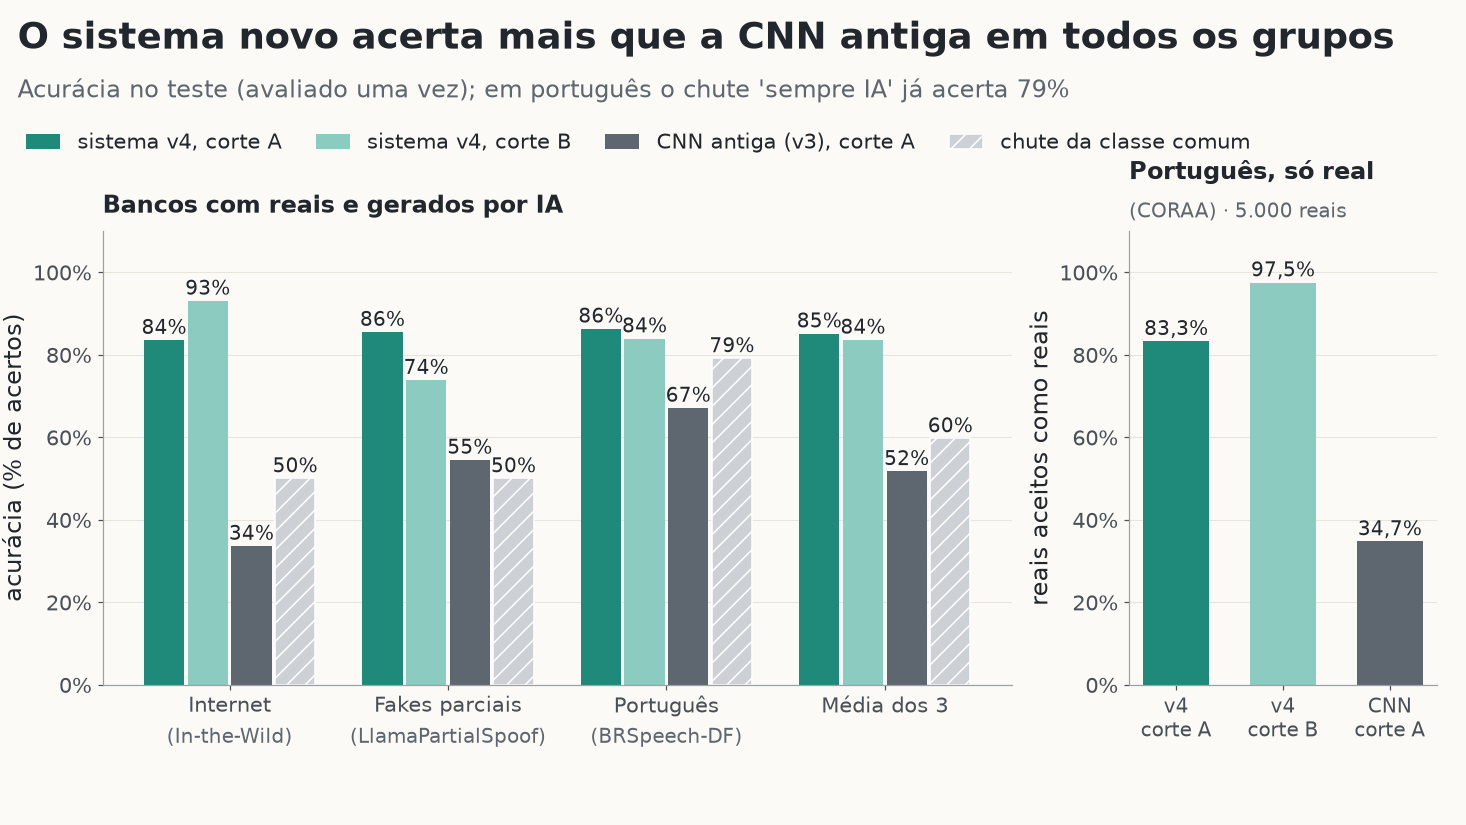

In [22]:
figura("09_acuracia_grupos")

**O que olhar:** na internet a CNN antiga fica **abaixo do chute** (34% contra 50%) e o v4 vai a 84% (A) e 93% (B); no português (BRSpeech-DF), com o corte A, o v4 (86%) passa pouco do chute (79%), porque 79% do banco é gerado por IA; no CORAA, o corte A aceita 83,3% dos reais e o B, 97,5%.

**O que concluir:** o sistema novo é muito melhor que a CNN em todos os grupos; a acurácia sozinha engana em banco desbalanceado (BRSpeech-DF, CORAA), por isso a acurácia balanceada e a AUC vêm junto (tabela acima).

### Figura 10 · Os dois tipos de erro, por grupo

**O que ela mostra:** à esquerda, a % de **reais acusados como IA** (o falso alarme); à direita, a % de **gerados por IA que passam sem alarme**; em cada grupo, a barra escura é o corte A e a clara o corte B. O CORAA só tem reais, então só aparece à esquerda.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/10_erros_por_grupo.png`.*

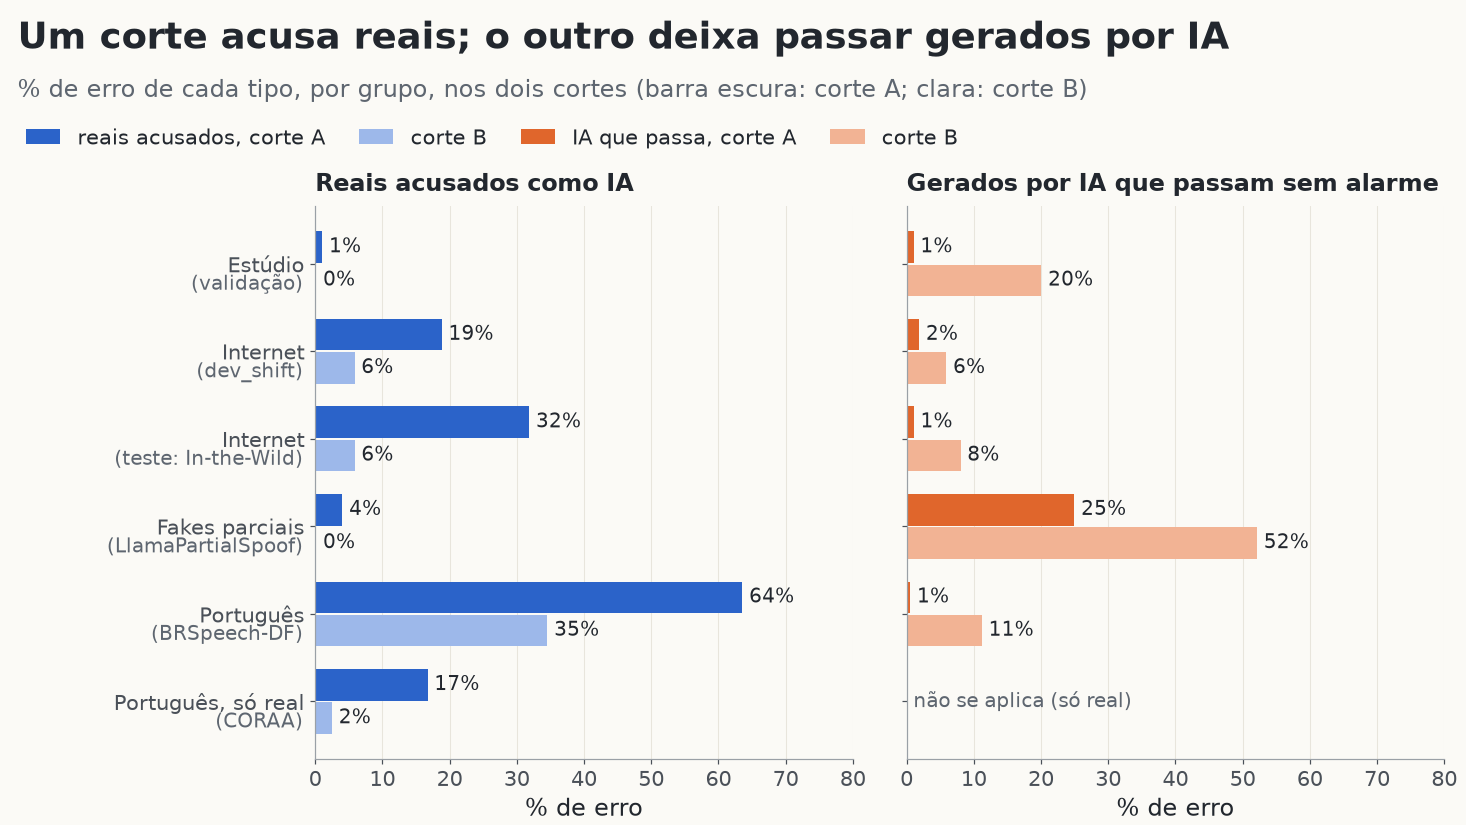

In [23]:
figura("10_erros_por_grupo")

**O que olhar:** com o corte A, os reais acusados são poucos no estúdio (1%) e muitos na internet (19% no dev_shift, 32% no teste) e no português (64% no BRSpeech-DF, 17% no CORAA); com o corte B, eles caem (6%, 6%, 35% e 2%), mas os gerados por IA que passam sobem: 52% nos fakes parciais e 20% no estúdio.

**O que concluir:** o corte escolhido no estúdio não serve para o mundo real, e o escolhido nas vozes de internet deixa passar fakes de outros tipos: nenhum corte único é bom em todos os grupos. Um corte por domínio é a ideia que ficou para depois (não testada).

### Figura 11 · A duração do áudio importa

**O que ela mostra:** a AUC do sistema separada pela duração **original** do arquivo (antes do corte de silêncio e do limite de 8 s): menos de 2 s, de 2 a 4 s e 4 s ou mais, nos três bancos principais do teste. O número dentro de cada barra é a quantidade de áudios na faixa.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/11_duracao.png`.*

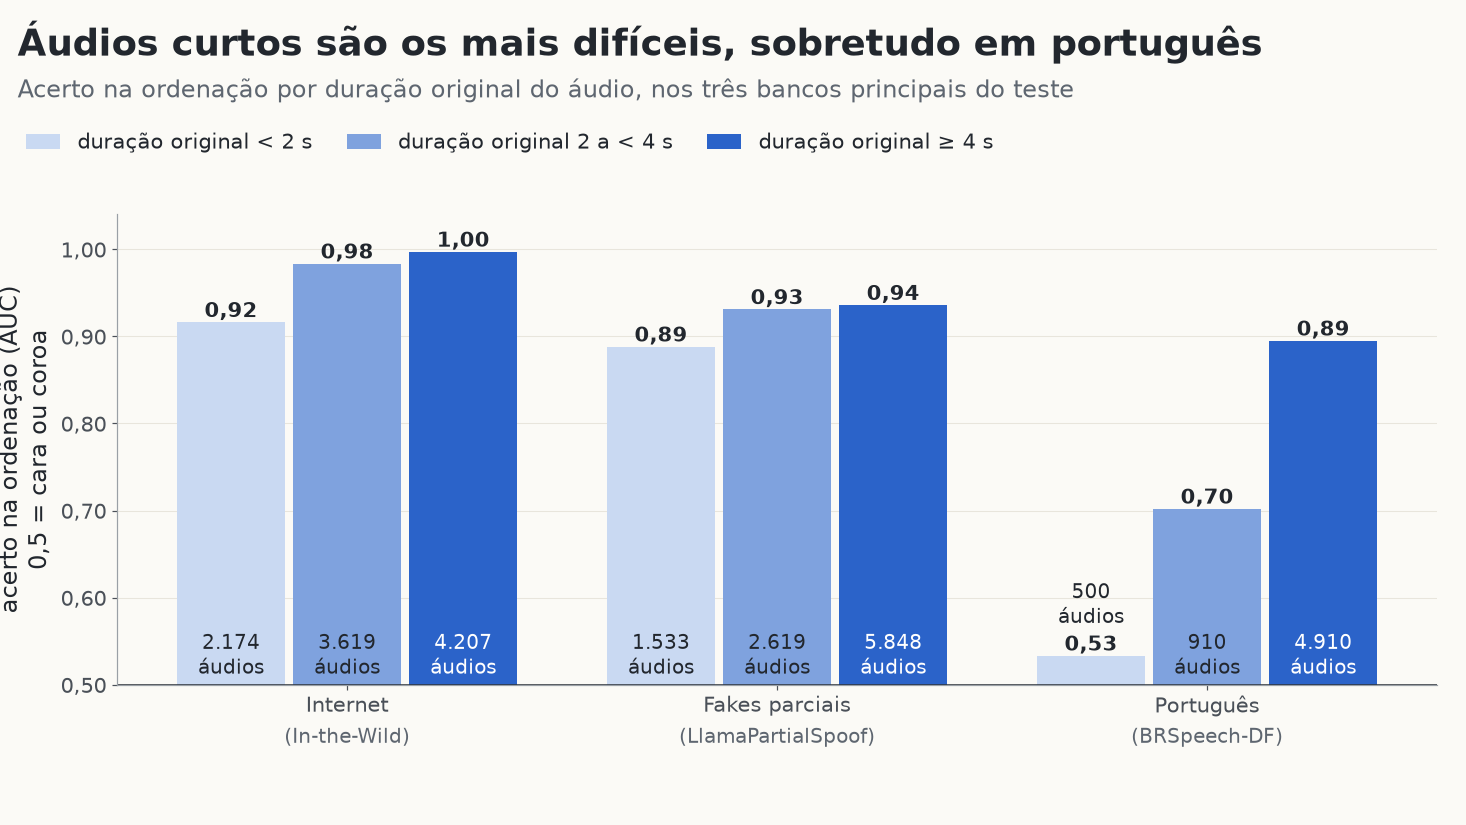

In [24]:
figura("11_duracao")

**O que olhar:** em todos os bancos os áudios curtos são os piores; no português, abaixo de 2 s a AUC é 0,53 (quase cara ou coroa, 500 áudios) e de 2 a 4 s é 0,70.

**O que concluir:** áudio curto é um ponto fraco geral, e o português curto é onde o sistema praticamente não funciona; a duração se mistura com outras diferenças (locutor, gravador), então é associação, não causa.

### Figura 14 · Todos os cortes possíveis de uma vez (curva ROC)

**O que ela mostra:** para cada corte possível, a % de reais acusados (eixo x) e a % de gerados por IA detectados (eixo y), nos três bancos principais. Uma curva colada no canto superior esquerdo é ótima; a diagonal é cara ou coroa. Os pontos marcam os cortes A (●) e B (■). ⚠️ Fora da trilha: a curva ROC (usada desde a v1).

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/14_roc.png`.*

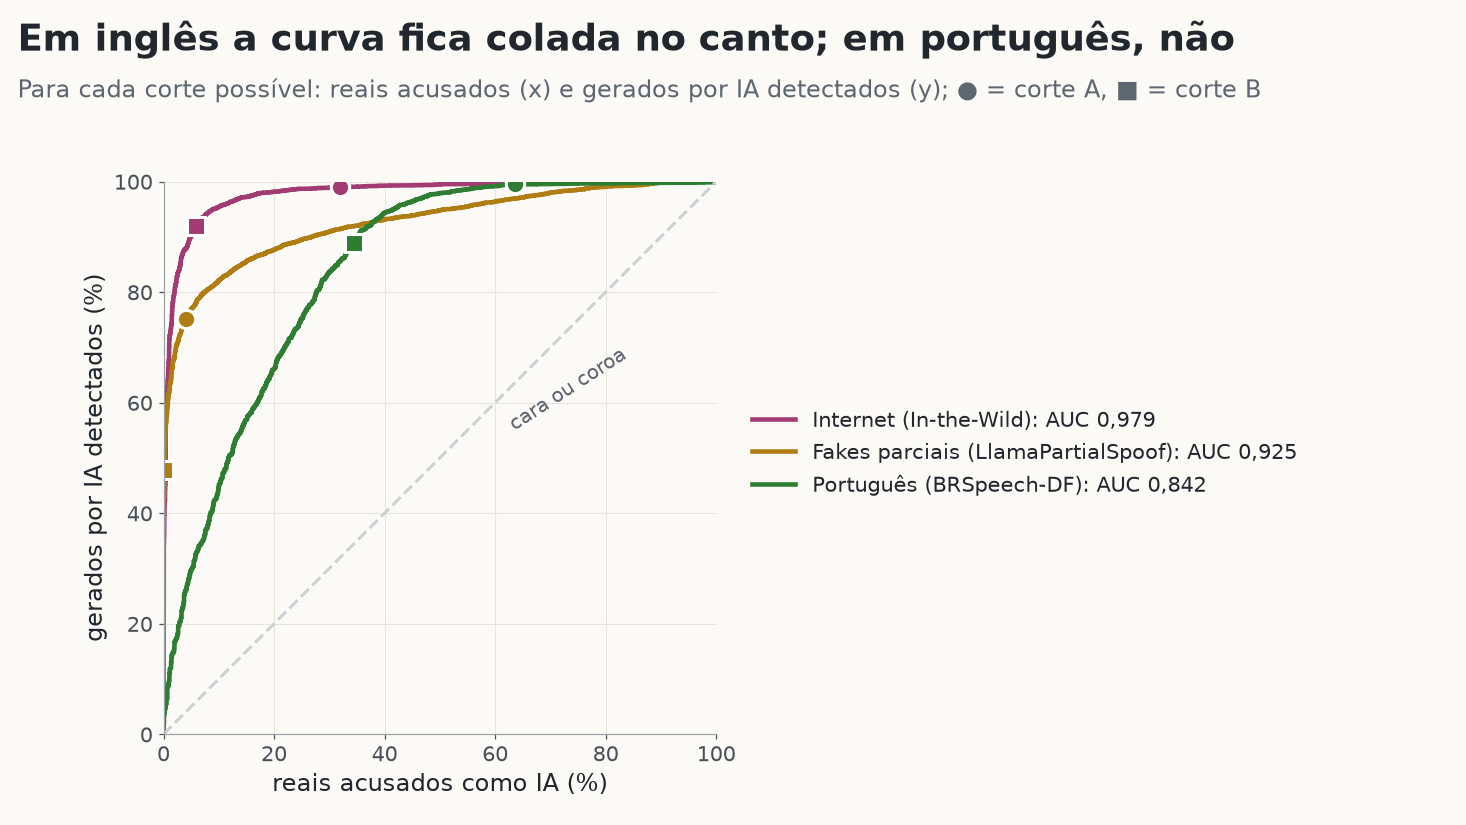

In [25]:
figura("14_roc")

**O que olhar:** as curvas da internet e dos fakes parciais ficam perto do canto; a do português fica bem abaixo; os pontos A e B ficam em lugares diferentes de cada curva.

**O que concluir:** a ordenação é boa em inglês (AUC 0,925 e 0,979) e fraca em português (0,842); a troca entre reais acusados e IA que passa depende do corte, e nenhum dos dois é bom em todos os bancos.

### G9 · Matrizes de confusão no teste, cortes A e B

**O que ela mostra:** as contagens de cada combinação (verdade × resposta do sistema) e a % por linha (linha = verdade), nos três bancos principais e no CORAA (só reais).

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Só no notebook.*

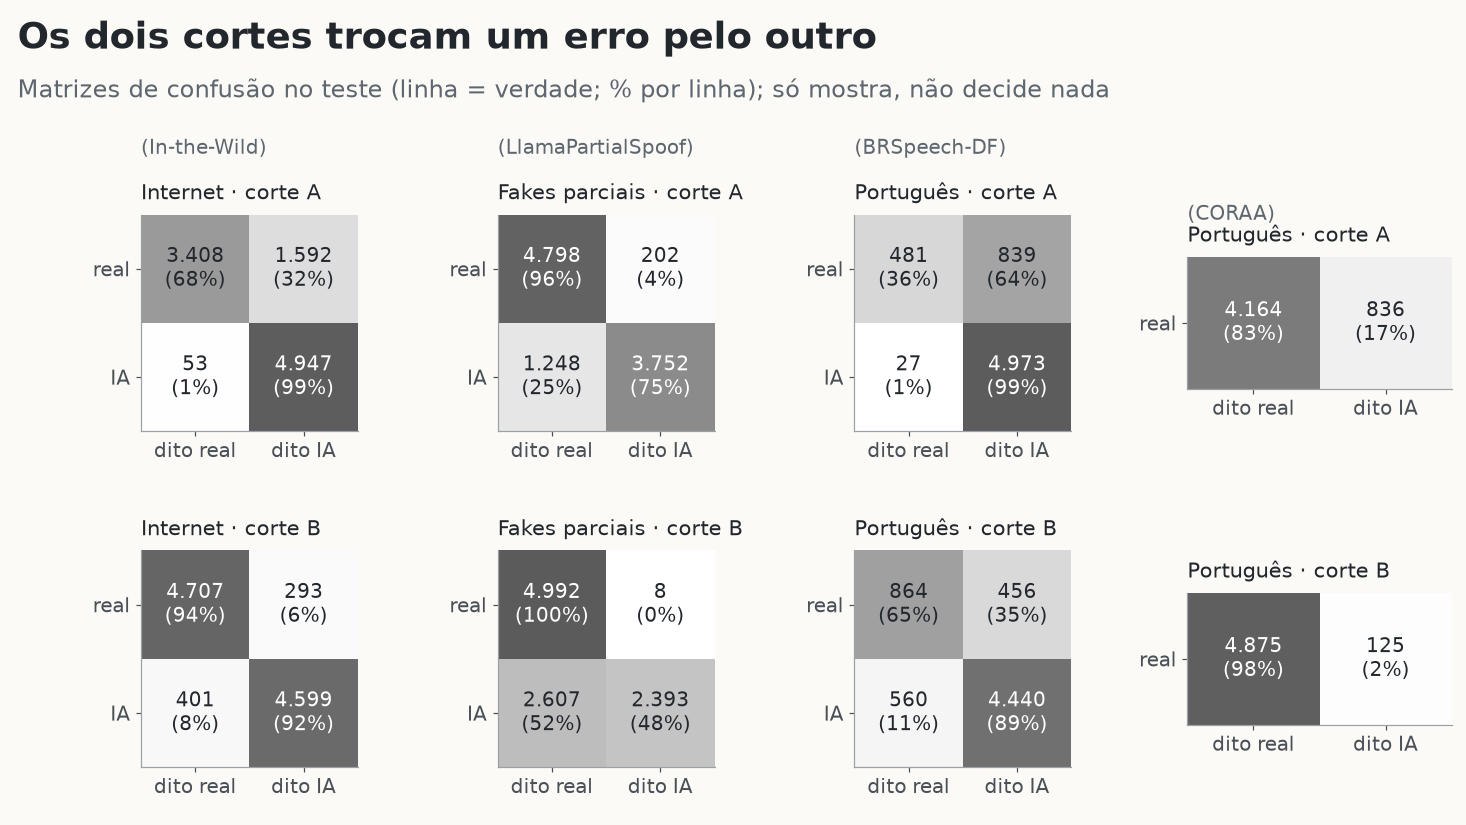

In [26]:
figura("g9_confusao")

**O que olhar:** no corte A, 32% dos reais da internet e 64% dos reais do BRSpeech-DF são acusados; no corte B, 52% dos gerados por IA do LlamaPartialSpoof passam.

**O que concluir:** os dois cortes trocam um erro pelo outro; o pior caso é o BRSpeech-DF, ruim nos dois.

### G1-teste · O plano da regressão nos bancos de teste (SÓ VISUALIZAÇÃO, NÃO DECIDE NADA)

**O que ela mostra:** o mesmo desenho da figura 03 (eixo x = nota; eixo y calculado no treino) para In-the-Wild, LlamaPartialSpoof, BRSpeech-DF e CORAA. Nada aqui foi usado para escolher qualquer coisa.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Só no notebook.*

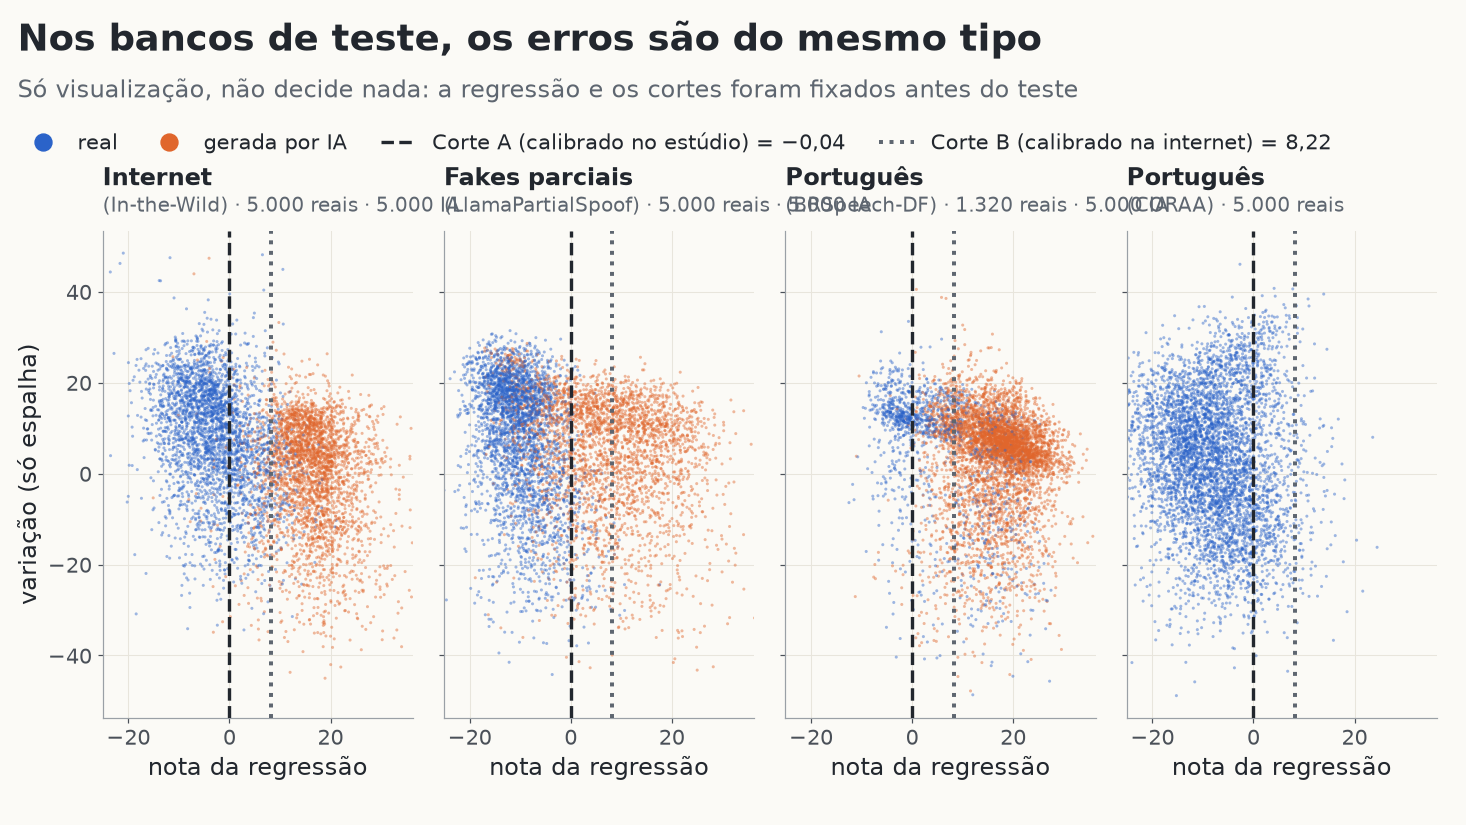

In [27]:
figura("g1_plano_decisao_teste")

**O que olhar:** no BRSpeech-DF uma boa parte dos reais (azul) fica à direita do corte A, e no CORAA também há reais à direita; no LlamaPartialSpoof, gerados por IA (laranja) à esquerda.

**O que concluir:** os erros do teste são do mesmo tipo do dev_shift (reais com nota alta, sobretudo em português) mais fakes parciais que passam; a figura não diz por quê, e não deve ser usada para mexer no corte.

### Figura 13 · Os testes secundários (ASVspoof)

**O que ela mostra:** acurácia (cortes A e B) e AUC do sistema v4 e da CNN antiga nos dois testes secundários, ASVspoof 2019 (parte eval) e ASVspoof 2021 DF. São **secundários** porque podem ter locutores em comum com o treino (o VCTK aparece anonimizado no ASVspoof e com nome no DFADD).

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/13_secundarios.png`.*

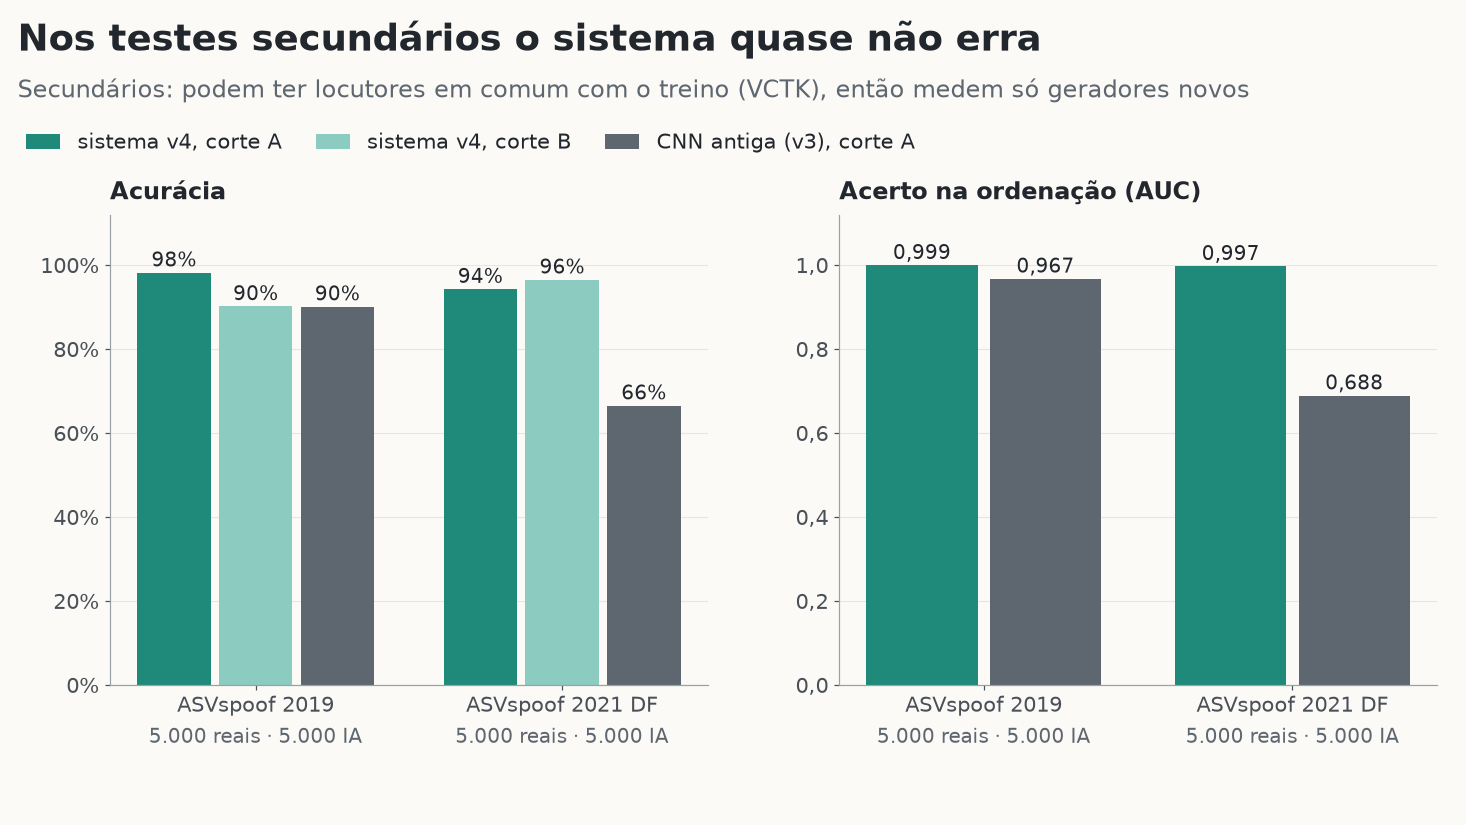

In [28]:
figura("13_secundarios")

**O que olhar:** no corte A, o v4 acerta 98% (2019) e 94% (2021), com AUC 0,999 e 0,997; a CNN antiga cai no 2021 (acurácia 66,5%, AUC 0,688).

**O que concluir:** números altos, mas valem só para **geradores novos**, não para pessoas novas; por isso não entram na média dos 3 principais.

**O que faz:** a média da acurácia dos 3 bancos principais (In-the-Wild, LlamaPartialSpoof, BRSpeech-DF), o falso alarme do CORAA à parte, e a leitura pré-definida das diferenças pareadas (S2 − S1 = "nossas escolhas"; S3 − S2 = "juntar a CNN"). **Por quê:** é o resumo combinado antes do teste.

In [29]:
tr = ler(R / "v4_teste_final_resumo.json")
res = pd.DataFrame(tr["resumo"]).replace({"sistema": {"S2": "S2 = F0"}})
display(res.round(3))
display(Markdown("**Leitura pré-definida** (relevante só com o mesmo sinal nos 3 principais e IC95 sem o zero em cada um):"))
display(pd.Series(tr["regra_leitura"]).to_frame("resultado"))
dif = pd.read_csv(R / "v4_teste_diferencas.csv")
display(dif.round(4))

,sistema,limiar,média acurácia (3 principais),média acurácia balanceada (3 principais),média acurácia trivial (3 principais),média AUC (3 principais),coraa falso alarme,coraa falso alarme IC
0,S0,A,0.517,0.529,0.597,0.468,0.653,"[0.638795, 0.666]"
1,S0,B,0.384,0.438,0.597,0.468,0.413,"[0.399, 0.427]"
2,S1,A,0.843,0.784,0.597,0.899,0.356,"[0.342, 0.3688]"
3,S1,B,0.814,0.798,0.597,0.899,0.116,"[0.106595, 0.1252]"
4,S2 = F0,A,0.851,0.790,0.597,0.915,0.167,"[0.1568, 0.178]"
5,S2 = F0,B,0.836,0.813,0.597,0.915,0.025,"[0.0208, 0.0292]"
6,S3,A,0.778,0.728,0.597,0.876,0.318,"[0.3056, 0.3316]"
7,S3,B,0.767,0.763,0.597,0.876,0.087,"[0.0788, 0.0942]"


**Leitura pré-definida** (relevante só com o mesmo sinal nos 3 principais e IC95 sem o zero em cada um):

,resultado
contribuição das nossas escolhas (S2 − S1) | AUC,não demonstrada
"contribuição das nossas escolhas (S2 − S1) | acurácia balanceada, limiar A",não demonstrada
contribuição da CNN (S3 − S2) | AUC,não demonstrada
"contribuição da CNN (S3 − S2) | acurácia balanceada, limiar A",não demonstrada


,leitura,métrica,banco,tipo,diferença,"IC 2,5%","IC 97,5%",IC exclui zero
0,contribuição das nossas escolhas (S2 − S1),AUC,in_the_wild,principal,-0.0078,-0.0102,-0.0056,True
1,contribuição das nossas escolhas (S2 − S1),AUC,llamapartialspoof,principal,-0.0106,-0.0146,-0.0066,True
2,contribuição das nossas escolhas (S2 − S1),AUC,brspeech_df,principal,0.0661,0.0577,0.0753,True
3,contribuição das nossas escolhas (S2 − S1),AUC,asvspoof2019_la,secundário,0.0022,0.0015,0.0028,True
4,contribuição das nossas escolhas (S2 − S1),AUC,asvspoof2021_df,secundário,0.0006,-0.0002,0.0014,False
5,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",in_the_wild,principal,0.0063,-0.0011,0.0136,False
6,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",llamapartialspoof,principal,0.0039,-0.0022,0.0095,False
7,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",brspeech_df,principal,0.0081,-0.0011,0.0178,False
8,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",asvspoof2019_la,secundário,0.0072,0.0042,0.0103,True
9,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",asvspoof2021_df,secundário,-0.0144,-0.0192,-0.0095,True


**Conclusão do teste:**
- **F0:** AUC 0,979 (In-the-Wild), 0,925 (LlamaPartialSpoof), 0,842 (BRSpeech-DF); média da acurácia nos 3 principais **0,851** (corte A) e 0,836 (B), contra **0,597** do chute da classe comum. CORAA: 16,7% (A) e 2,5% (B) dos reais acusados.
- **Secundários** (ASVspoof 2019 e 2021 DF, AUC 0,999 e 0,997): números altos, mas esses bancos podem ter locutores em comum com o treino (VCTK, via DFADD), então valem para geradores novos, não para locutores novos.
- **Nossas escolhas × só a última camada (S2 − S1): não demonstrada.** AUC −0,008 (In-the-Wild), −0,011 (LlamaPartialSpoof), +0,066 (BRSpeech-DF): sinais trocados. A única diferença grande a favor do F0 é no português (e no CORAA, 35,6% → 16,7% de reais acusados no corte A, só reportado).
- **CNN (S0) e juntar a CNN (S3):** a CNN tem AUC 0,114 no In-the-Wild, bem abaixo de 0,5: ela erra de forma sistemática, dando nota de IA mais alta aos reais; juntar a CNN ao F0 piorou o In-the-Wild em 0,091 de AUC.
- **Bootstrap:** os intervalos (±0,001 a ±0,016) medem **só a amostra de teste**; não medem o acaso do treino (uma única amostra de treino e uma regressão), que a v3 mostrou ser grande para a CNN.

## 9. O caminho até aqui (v1 a v6)

| versão | o que foi tentado | resultado | conclusão |
|:--|:--|:--|:--|
| v1 | CNN pequena em log-mel, sem augmentation | validação EER 1,3%; In-the-Wild AUC 0,211 | ótima em casa; na internet, abaixo de cara ou coroa (erra de forma sistemática) |
| v2 | regra do checkpoint (v1r), volume (v2a), ruído e canal (v2b); criação do dev_shift | dev_shift AUC 0,325 / 0,386 / 0,389 | robusta ao ruído que viu, sem ganho além do acaso; "limpo = real" não se confirmou |
| v3 | repetir × completar com zeros, 3 seeds | dev_shift AUC 0,146 a 0,378 nas seis execuções | sem efeito; a lição foi o **tamanho do acaso** |
| **v4** | **XLS-R congelado + regressão logística** (F0) | dev_shift 0,983; In-the-Wild 0,979; média de acurácia 0,851 | resolveu o erro sistemático na internet; fraco em português |
| v5 | o WavLM da Microsoft no lugar do XLS-R da Meta, mesmo pipeline | empate no dev_shift; pior no teste em AUC nos 3 principais | segue o XLS-R |
| v6 | funil: Meta × Microsoft, fusão, RL × MLP × CNN, ajuste fino (pela AUC da pior fonte) | F2: média de acurácia 0,829 | pior que o F0 no teste; o notebook voltou ao F0 |

**A régua do ruído (v3):** com a mesma receita e só a seed mudando, a AUC do dev_shift da CNN variou de 0,146 a 0,378 (amplitude ~0,15 a 0,23); a acurácia balanceada, de 0,365 a 0,503. Diferenças menores que isso entre execuções únicas não são efeito. Na v4, as somas ponderadas com 3 seeds variaram só ~0,005 de AUC no dev_shift: com o modelo pronto, o acaso ficou muito menor.

**Hiperparâmetros de cada versão.** A tabela abaixo (`results/slides/hiperparametros_versoes.csv`) foi montada a partir das células de configuração dos notebooks arquivados, do código (`src/`, `scripts/`) e de `docs/HISTORICO_VERSOES.md`. A coluna "por que esse valor" só tem o que o histórico ou o código explicam ("não documentado" quando não há); "efeito observado" só tem o que foi medido ("não medido" quando não há). A v5 não está na tabela: ela repetiu a v4 trocando só o modelo pronto.

**O que faz:** mostra a tabela de hiperparâmetros, uma coluna por versão. **Por quê:** comparar as receitas lado a lado.

In [30]:
hp = pd.read_csv(SLIDES / "hiperparametros_versoes.csv") if existe(SLIDES / "hiperparametros_versoes.csv") else None
if hp is not None:
    display(Markdown(hp.set_index("versão").T.reset_index().rename(columns={"index": "item"}).to_markdown(index=False)))
else:
    pendente("`results/slides/hiperparametros_versoes.csv`")

| item                      | v1 (baseline)                                                                                                                                                                                                                                                      | v2 (v1r, v2a, v2b)                                                                                                                                                                                                               | v3 (repeat × zero)                                                                                                                     | v4 (F0, sistema final)                                                                                                                                                                               | v6 (F2, saída do funil)                                                                                                             | v6 (E4: MLP desafiante)                                                             | v6 (E4: CNN desafiante)                                                                                                         |
|:--------------------------|:-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:---------------------------------------------------------------------------------------------------------------------------------------|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:------------------------------------------------------------------------------------------------------------------------------------|:------------------------------------------------------------------------------------|:--------------------------------------------------------------------------------------------------------------------------------|
| entrada                   | 16 kHz mono; recorte de 4 s (aleatório no treino, central na validação); áudio curto repetido; log-mel 64 faixas (n_fft 512, janela 400, passo 160), padronizado por áudio                                                                                         | igual à v1; teste por janelas de 4 s com passo de 2 s (média dos logits)                                                                                                                                                         | igual à v1r; áudio < 4 s repetido (repeat) ou completado com zeros à direita (zero)                                                    | 16 kHz mono; corte de silêncio nas bordas (35 dB; se sobrar < 0,5 s, não corta); até 8 s do meio, sem completar; sem log-mel (o XLS-R lê a onda)                                                     | igual à v4                                                                                                                          | a mesma da RL básica (camada 11, média)                                             | as 25 saídas do XLS-R (média e desvio: 25 × 2.048)                                                                              |
| arquitetura               | CNN: 4 blocos Conv 3×3 + BatchNorm + ReLU + MaxPool (16/32/64/128 filtros), Dropout, Linear(1); 110.433 parâmetros                                                                                                                                                 | igual à v1                                                                                                                                                                                                                       | igual à v1                                                                                                                             | XLS-R 300M da Meta congelado (24 camadas, 1.024 números a cada 20 ms); média no tempo das camadas 5, 6 e 7 (3.072 números) + regressão logística (3.073 parâmetros)                                  | XLS-R congelado, só a camada 11 + regressão logística (1.025 parâmetros)                                                            | MLP: 1 camada escondida de 256, ReLU, dropout; 262.657 parâmetros                   | CNN ao longo das camadas: Conv1d(2048→64, k=3) + BatchNorm + ReLU, Conv1d(64→64, k=3) + ReLU, média, Linear; 405.825 parâmetros |
| épocas (máx. / escolhida) | 30 / 16 (parou na 21; early stopping, paciência 5, pela EER global da validação)                                                                                                                                                                                   | 30 / 13, 20, 17 (v1r, v2a, v2b; checkpoint pela EER média por fonte)                                                                                                                                                             | 30 / repeat 9, 12, 9; zero 7, 19, 11 (seeds 42, 123, 2026)                                                                             | não se aplica: lbfgs até 1.000 iterações (convergiu em 56)                                                                                                                                           | não se aplica (lbfgs)                                                                                                               | 30 / 4, 2, 3 (seeds 42, 123, 2026; paciência 5)                                     | 30 / 11, 5, 9 (seeds 42, 123, 2026; paciência 5)                                                                                |
| lote                      | 64 (25.000 reais + 25.000 IA por época)                                                                                                                                                                                                                            | 64                                                                                                                                                                                                                               | 64                                                                                                                                     | não se aplica (lbfgs usa os 40.000 áudios de treino de uma vez)                                                                                                                                      | não se aplica                                                                                                                       | 256                                                                                 | 256                                                                                                                             |
| otimizador e taxa         | Adam, 0,001                                                                                                                                                                                                                                                        | Adam, 0,001                                                                                                                                                                                                                      | Adam, 0,001                                                                                                                            | lbfgs do scikit-learn (tolerância 0,0001), sem taxa de aprendizado                                                                                                                                   | lbfgs do scikit-learn                                                                                                               | AdamW, 0,001                                                                        | AdamW, 0,001                                                                                                                    |
| regularização             | dropout 0,3; sem weight decay; early stopping                                                                                                                                                                                                                      | dropout 0,3; sem weight decay; early stopping (paciência 5)                                                                                                                                                                      | dropout 0,3; sem weight decay; early stopping (paciência 5)                                                                            | L2 com C = 0,1 (grade 0,001 / 0,01 / 0,1 / 1)                                                                                                                                                        | L2 com C = 1; pesos iguais por fonte de treino                                                                                      | dropout 0,3; weight decay 0,001; early stopping                                     | weight decay 0,001; early stopping                                                                                              |
| augmentation              | nenhuma (de propósito)                                                                                                                                                                                                                                             | v1r: nenhuma; v2a: volume (RMS −26 dB e ganho −12 a +6 dB, chance 0,5 cada); v2b: v2a + ruído branco/rosa/marrom (SNR 5 a 30 dB), banda de telefone (8 kHz) e mu-law 8 bits, chance 0,3 cada                                     | nenhuma                                                                                                                                | nenhuma                                                                                                                                                                                              | nenhuma                                                                                                                             | nenhuma                                                                             | nenhuma                                                                                                                         |
| seeds                     | 42                                                                                                                                                                                                                                                                 | 42 (uma execução por experimento)                                                                                                                                                                                                | 42, 123 e 2026 (3 por condição)                                                                                                        | 42 (dados); a regressão é determinística                                                                                                                                                             | 42 (dados; bootstrap 2.000 reamostragens)                                                                                           | 42, 123 e 2026                                                                      | 42, 123 e 2026                                                                                                                  |
| camadas do XLS-R          | —                                                                                                                                                                                                                                                                  | —                                                                                                                                                                                                                                | —                                                                                                                                      | 5, 6 e 7                                                                                                                                                                                             | 11                                                                                                                                  | 11                                                                                  | todas (0 a 24)                                                                                                                  |
| por que esse valor        | 4 s: mediana de duração da maioria dos bancos; 64 faixas: entrada pequena para uma CNN pequena; lote 64 e Adam 0,001: Aula 6; dropout 0,3: regularização moderada da Aula 7; paciência 5: early stopping da Aula 7; sem augmentation: primeiro medir o modelo puro | RMS −26 dB: nível típico de fala (EDA da v1); SNR 5 a 30 dB: de ruído forte a quase limpo; 8 kHz e mu-law: telefonia; chance 0,3: ~1/3 dos exemplos continua limpo; checkpoint pela EER média por fonte: a validação é 79% DFADD | 3 seeds: medir o acaso do treino (a v2 não separava efeito de acaso); recorte determinístico: as duas condições veem os mesmos trechos | C = 0,1 e as camadas 5, 6, 7: menor EER média por fonte na validação (5,92%); 8 s: o dobro dos 4 s, ~90% dos áudios cabem inteiros; 40.000 áudios: o maior treino em que o teto por fonte ainda vale | camada 11 e C = 1: maior AUC da pior fonte (validação + dev_shift); pesos por fonte: +0,006 na pior fonte, passou a régua de +0,003 | a MLP da v4, sem ajuste novo; o early stopping evita overfitting                    | uma CNN pequena (2 convoluções) para não ter muito mais parâmetros que o MLP                                                    |
| efeito observado          | validação EER 1,3%; In-the-Wild AUC 0,211 (ordena ao contrário); CORAA 41,6% de reais acusados                                                                                                                                                                     | dev_shift AUC 0,325 / 0,386 / 0,389: sem ganho além do acaso; v2b robusto às degradações que viu                                                                                                                                 | padding sem efeito demonstrado; AUC do dev_shift de 0,146 a 0,378 só mudando a seed (a régua do acaso)                                 | dev_shift AUC 0,983; In-the-Wild 0,979; ganho sobre só a última camada não demonstrado; corte de silêncio sem efeito (ablação); com mais freio o dev_shift melhora (diagnóstico, figura 07)          | pior que a v4 no teste (média da acurácia 0,829 × 0,851; BRSpeech-DF AUC 0,744 × 0,842)                                             | AUC da pior fonte 0,902 a 0,912 × 0,904 da RL: nenhuma seed com diferença relevante | AUC da pior fonte 0,906 a 0,910 × 0,904 da RL: nenhuma seed com diferença relevante                                             |
| fonte                     | docs/HISTORICO_VERSOES.md (v1); notebooks/versions/v1_baseline.ipynb, seção 2                                                                                                                                                                                      | docs/HISTORICO_VERSOES.md (v2); notebooks/versions/v2_augmentation.ipynb, seção 2                                                                                                                                                | docs/HISTORICO_VERSOES.md (v3, pré-registro e fechamento); notebooks/versions/v3_padding.ipynb                                         | docs/HISTORICO_VERSOES.md (v4); notebooks/versions/v4_ssl.ipynb, seção 2; results/v4_*                                                                                                               | docs/HISTORICO_VERSOES.md (v6); notebooks/versions/v6_funil.ipynb, seção 2; results/v6_funil.csv                                    | docs/HISTORICO_VERSOES.md (v6, E4); results/v6_e4_cabecas.csv                       | docs/HISTORICO_VERSOES.md (v6, pré-registro E4); results/v6_e4_cabecas.csv                                                      |

### Figura 12 · Meta × Microsoft, camada por camada (v5)

**O que ela mostra:** na v5, o mesmo pipeline da v4 com o WavLM da Microsoft (só inglês) no lugar do XLS-R da Meta (128 línguas), nos mesmos áudios. Para cada camada, uma regressão: à esquerda, o erro no estúdio (EER média por fonte na validação); à direita, a AUC na internet (dev_shift). A faixa verde marca as camadas do sistema final.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/12_meta_microsoft.png`.*

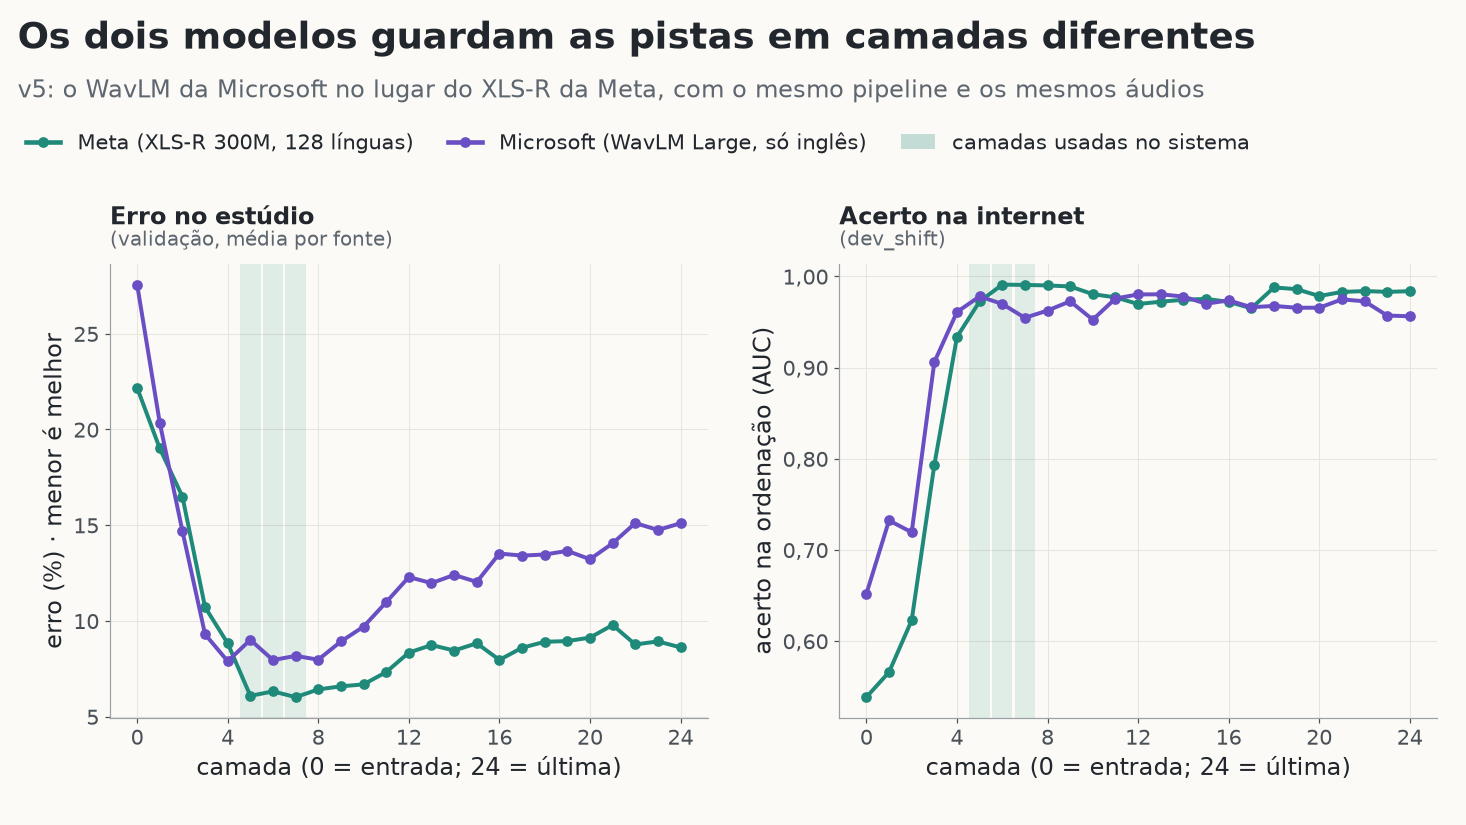

In [31]:
figura("12_meta_microsoft")

**O que olhar:** no WavLM as melhores camadas são as de baixo (3 e 4) e a qualidade cai depois da 8; no XLS-R as camadas 5 a 9 ficam todas boas e as de cima pioram pouco.

**O que concluir:** os dois modelos guardam as pistas em lugares diferentes, e o XLS-R foi melhor no conjunto (sobretudo em português, no teste da v5: BRSpeech-DF AUC 0,842 × 0,768). A explicação (o pré-treino do WavLM a "limpar" ruído descartaria os detalhes acústicos nas camadas de cima) é hipótese, não testada. A v6 refez a comparação nos mesmos áudios e chegou ao mesmo lugar.

**O funil da v6:** cada etapa comparou candidatos pela AUC da pior fonte (validação + dev_shift), com bootstrap por locutor, e só deixava entrar algo mais complexo com diferença relevante.

**O que faz:** mostra `results/v6_funil.csv` e os finalistas F0, F1 e F2 lado a lado no teste, com a acurácia trivial. **Por quê:** é a evidência de por que o notebook voltou ao F0.

In [32]:
fun = pd.read_csv(R / "v6_funil.csv")
display(fun[["etapa", "vencedor", "por quê", "AUC pior fonte (cada candidato)"]])
f012 = pd.read_csv(R / "v4final_f0_f1_f2.csv")
display(Markdown("**F0, F1 e F2 no teste (corte A; F1 = camada 11, C = 1; F2 = F1 + pesos iguais por fonte):**"))
p = f012[f012.limiar == "A"].pivot_table(index="banco", columns="sistema", values=["acurácia", "acurácia balanceada", "AUC", "falso alarme real"], sort=False)
p[("acurácia trivial", "")] = f012[(f012.limiar == "A") & (f012.sistema == "F0")].set_index("banco")["acurácia trivial"]
display(p.round(3))

,etapa,vencedor,por quê,AUC pior fonte (cada candidato)
0,E1 Meta × Microsoft,empate (a E3 decide: fica o mais simples),Microsoft − Meta = -0.0166 (IC95 -0.0481 a +0.0011),Meta (concat_top4): 0.9072; Microsoft (concat_top3): 0.8906; v4 (referência)...
1,E2 fusão,fusão: média das notas,fica fusao_media: fusao_stacking − fusao_media: +0.0004 (IC95 -0.0005 a +0.0...,fusão: média das notas: 0.9051; fusão: stacking: 0.9055; fusão: vetores cola...
2,E3 front-end,só Meta (XLS-R),fica xlsr: wavlm − xlsr: -0.0166 (IC95 -0.0481 a +0.0011) → não relevante; f...,só Meta (XLS-R): 0.9072; só Microsoft (WavLM): 0.8906; fusão: média das nota...
3,E4 cabeças básicas,RL,"fica RL: MLP − RL por seed: +0.0079, +0.0018, -0.0015 → não relevante nas 3;...",RL básica: 0.9037; MLP básico s42: 0.9116; MLP básico s123: 0.9056; MLP bási...
4,E5 maximização,pesos iguais por fonte (sample_weight),pior fonte final 0.9100; regra de limiar A,passo 1: zona de camadas: {'xlsr': [11]}: 0.9037; passo 2: grade ampla de C:...
5,"E6 teste (uma vez, só mostra)",— (o teste não escolhe),F0: média da acurácia nos 3 principais 0.851 (trivial 0.597); F1: média da a...,"F0: v4: XLS-R (Meta) concat_top3 (camadas 5, 6, 7) + RL, C = 0,1: 0.9031; F1..."


**F0, F1 e F2 no teste (corte A; F1 = camada 11, C = 1; F2 = F1 + pesos iguais por fonte):**

acurácia               acurácia balanceada                  AUC               falso alarme real               acurácia trivial
sistema                 F0     F1     F2                  F0     F1     F2     F0     F1     F2                F0     F1     F2                 
banco                                                                                                                                           
in_the_wild          0.836  0.807  0.812               0.835  0.807  0.812  0.979  0.972  0.972             0.318  0.377  0.366            0.500
llamapartialspoof    0.855  0.863  0.863               0.855  0.863  0.863  0.925  0.940  0.937             0.040  0.040  0.043            0.500
brspeech_df          0.863  0.814  0.813               0.679  0.576  0.571  0.842  0.741  0.744             0.636  0.833  0.845            0.791
coraa                0.833  0.588  0.596                 NaN    NaN    NaN    NaN    NaN    NaN             0.167  0.412  0.404            1.000
asvspoof2019_la      0.981  0.975  0.975               0.981  0.975  0.975  0.999  0.997  0.997             0.001  0.006  0.007            0.500
asvspoof2021_df      0.942  0.954  0.950               0.942  0.954  0.950  0.997  0.996  0.996             0.108  0.078  0.088            0.500

**A lição honesta da v6:** o sistema declarado pelo funil (F2) ficou **pior no teste que o F0** (média da acurácia nos 3 principais 0,829 × 0,851; BRSpeech-DF AUC 0,744 × 0,842; CORAA 40,4% × 16,7% de reais acusados no corte A). A validação e o dev_shift (16 locutores) **não distinguiram** os dois: na AUC da pior fonte, F0 0,903 e F2 0,910. Causas prováveis, todas **HIPÓTESES**: (1) F1 e F2 usam **uma** camada (a 11), o F0 usa **três** (5, 6, 7); (2) F1 e F2 usam C = 1 (freio fraco), o F0 usa C = 0,1 (a figura 07 sugere que mais freio generaliza melhor); (3) a "pior fonte" foi sempre o CodecFake+ (352 áudios, inglês, codec), que não representa o português.

## 10. Limitações

- **Os bancos de teste foram vistos três vezes** (v4, v5 e v6). Os números do F0 são os da v4 original (o primeiro olhar), mas os bancos já não são "nunca vistos".
- **dev_shift pequeno:** 16 locutores; é ele que define o corte B e que decidiu entre versões.
- **Uma única amostra de treino** (40.000 áudios) e uma regressão: o bootstrap do teste não mede o acaso do treino.
- **O português é o ponto fraco:** BRSpeech-DF com acurácia balanceada ~0,68 no corte A (0,77 no B); áudios de menos de 2 s quase em cara ou coroa (figura 11); CORAA com 16,7% de reais acusados no corte A.
- **Os dois cortes trocam um erro pelo outro:** A acusa reais de internet e de português; B deixa passar fakes parciais e de codec (figura 10).
- **A decisão de voltar ao F0 veio depois de ver o teste da v6.** O F0 em si foi escolhido pela validação **antes de qualquer teste** (pré-registro da v4), por isso os números do F0 são os da v4 original; mas preferir o F0 ao F2 agora é uma escolha informada pelo teste. **Recomendação:** antes de apresentar um número final como definitivo, avaliar o F0 **uma vez** num banco nunca visto, com o corte declarado antes.
- **Explicações não provadas:** por que o modelo pronto funciona (seção 4), por que as camadas do meio são as melhores, por que MLP e CNN não ganham, por que o WavLM perdeu e por que o F2 piorou são hipóteses.

## 11. Próximos passos (não executados)

1. **Melhorar a regressão logística:** por exemplo, testar um freio mais forte (figura 07), sempre escolhendo pela validação + dev_shift e confirmando num banco novo.
2. **Dados em português e fala espontânea no treino** (reais pt-BR e gerados por IA em pt-BR de geradores fora dos testes), e um conjunto de decisão em português, para que as escolhas deixem de piorar o português sem ninguém ver.
3. **O contexto de golpes:** áudio curto, de telefone ou de aplicativo de mensagem, onde o sistema é mais fraco (figura 11); definir o corte pelo custo de cada erro nesse uso.
4. **O modelo final unificado:** um único pipeline (áudio → XLS-R → regressão → nota e decisão) empacotado para o grupo, com o corte e o domínio de uso escritos junto.